In [ ]:

# STEP 1: Import required libraries

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Setup completed successfully!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)


Setup completed successfully!
NumPy: 2.1.3
Pandas: 2.2.3
TensorFlow: 2.21.0


In [ ]:

# STEP 2: Connect Google Drive

from google.colab import drive

drive.mount("/content/drive")

print("Google Drive connected successfully!")


Mounted at /content/drive
Google Drive connected successfully!


In [ ]:

import os

drive_root = "/content/drive/MyDrive"
matches = []

for root, dirs, files in os.walk(drive_root):
    # Skip unnecessary system folders
    dirs[:] = [
        d for d in dirs
        if d not in [".ipynb_checkpoints", "node_modules"]
    ]

    for filename in files:
        if "faststorage" in filename.lower():
            matches.append(os.path.join(root, filename))

print("Matching files found:", len(matches))

for path in matches:
    print(path)


Matching files found: 0


In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
print("\nCPU usage statistics:")
print(df["CPU usage [%]"].describe())

print("\nRows with CPU usage above 100%:",
      (df["CPU usage [%]"] > 100).sum())

print("\nMissing CPU values:",
      df["CPU usage [%]"].isna().sum())

print("\nFirst 5 timestamps:")
print(df["Timestamp [ms]"].head().tolist())

Saving 214_active.csv to 214_active.csv
Dataset shape: (7287, 11)

CPU usage statistics:
count    7287.000000
mean       68.457287
std        46.701443
min         0.250000
25%         0.375000
50%       102.475000
75%       104.775000
max       105.883333
Name: CPU usage [%], dtype: float64

Rows with CPU usage above 100%: 4272

Missing CPU values: 0

First 5 timestamps:
[1376314846, 1376315146, 1376315446, 1376315746, 1376316046]


In [ ]:
# Check how CPU usage percentage was calculated
df["calculated_cpu_pct"] = (
    df["CPU usage [MHZ]"]
    / df["CPU capacity provisioned [MHZ]"]
) * 100

print("First 10 recorded vs calculated CPU percentages:")
print(
    df[["CPU usage [%]", "calculated_cpu_pct"]]
    .head(10)
    .round(3)
)

print("\nMaximum absolute difference (% points):")
print(
    (df["CPU usage [%]"] - df["calculated_cpu_pct"])
    .abs()
    .max()
)

print("\nProvisioned CPU capacity:")
print(df["CPU capacity provisioned [MHZ]"].describe())

print("\nTimestamp differences:")
print(df["Timestamp [ms]"].diff().value_counts().head(10))

print("\nDuplicate timestamps:", df["Timestamp [ms]"].duplicated().sum())
print(
    "Timestamps in increasing order:",
    df["Timestamp [ms]"].is_monotonic_increasing
)

First 10 recorded vs calculated CPU percentages:
   CPU usage [%]  calculated_cpu_pct
0         75.600              75.600
1         66.217              66.217
2         61.592              61.592
3         35.783              35.783
4         41.325              41.325
5          6.658               6.658
6          0.333               0.333
7          0.342               0.342
8          0.342               0.342
9          0.342               0.342

Maximum absolute difference (% points):
5.684341886080802e-14

Provisioned CPU capacity:
count     7287.000000
mean     20799.995341
std          0.001067
min      20799.991928
25%      20799.994400
50%      20799.995600
75%      20799.996816
max      20799.996816
Name: CPU capacity provisioned [MHZ], dtype: float64

Timestamp differences:
Timestamp [ms]
300.0    6995
301.0     238
299.0      38
600.0       7
900.0       5
303.0       1
310.0       1
901.0       1
Name: count, dtype: int64

Duplicate timestamps: 0
Timestamps in increasin

In [ ]:
# Check time intervals without changing the original data
time_diff = df["Timestamp [ms]"].diff()

print("Time interval counts:")
print(time_diff.value_counts().sort_index())

print("\nRows where the gap is greater than 300 seconds:")
gap_rows = df.loc[time_diff > 300, ["Timestamp [ms]", "CPU usage [%]"]].copy()
gap_rows["gap_seconds"] = time_diff[time_diff > 300]
print(gap_rows.head(20))

print("\nTotal gaps greater than 300 seconds:", len(gap_rows))

Time interval counts:
Timestamp [ms]
299.0      38
300.0    6995
301.0     238
303.0       1
310.0       1
600.0       7
900.0       5
901.0       1
Name: count, dtype: int64

Rows where the gap is greater than 300 seconds:
     Timestamp [ms]  CPU usage [%]  gap_seconds
26       1376322647     101.500000        301.0
78       1376338248     101.966667        301.0
113      1376348749     102.141667        301.0
148      1376359250      97.233333        301.0
166      1376364650      96.925000        301.0
196      1376373651     102.075000        301.0
233      1376384752     101.766667        301.0
260      1376392853      24.175000        301.0
280      1376398853      22.708333        301.0
307      1376406954     102.108333        301.0
328      1376413255     102.416667        301.0
360      1376422856     104.125000        301.0
419      1376440557      99.075000        301.0
449      1376449558      43.441667        301.0
475      1376457359      14.625000        301.0
494     

In [ ]:
# Create a temporary timestamp-checking table
time_diff = df["Timestamp [ms]"].diff()

# Intervals of 299, 300, or 301 seconds are provisionally normal
normal_interval = time_diff.between(299, 301)

# Identify larger gaps
large_gaps = df.loc[
    time_diff > 301,
    ["Timestamp [ms]", "CPU usage [%]"]
].copy()

large_gaps["gap_seconds"] = time_diff[time_diff > 301]
large_gaps["gap_minutes"] = large_gaps["gap_seconds"] / 60

print("Expected interval: 300 seconds (5 minutes)")
print("Intervals within 299–301 seconds:", int(normal_interval.sum()))
print("Intervals greater than 301 seconds:", len(large_gaps))

print("\nLarger-gap distribution:")
print(large_gaps["gap_seconds"].value_counts().sort_index())

print("\nFirst 15 larger gaps:")
print(large_gaps.head(15).to_string(index=False))

# Check timestamp interpretation
df["timestamp_utc_check"] = pd.to_datetime(
    df["Timestamp [ms]"], unit="s", utc=True
)

print("\nFirst 5 timestamps interpreted as Unix seconds (UTC):")
print(df["timestamp_utc_check"].head().to_string(index=False))

Expected interval: 300 seconds (5 minutes)
Intervals within 299–301 seconds: 7271
Intervals greater than 301 seconds: 15

Larger-gap distribution:
gap_seconds
303.0    1
310.0    1
600.0    7
900.0    5
901.0    1
Name: count, dtype: int64

First 15 larger gaps:
 Timestamp [ms]  CPU usage [%]  gap_seconds  gap_minutes
     1376776891     105.066667        303.0     5.050000
     1376994123     103.050000        310.0     5.166667
     1377206844       0.341667        900.0    15.000000
     1377208044       0.358333        600.0    10.000000
     1377209845       0.358333        901.0    15.016667
     1377424064       0.341667        600.0    10.000000
     1377514671       0.375000        900.0    15.000000
     1377515571       0.350000        900.0    15.000000
     1377617579     105.291667        600.0    10.000000
     1377738188     104.875000        600.0    10.000000
     1378391949       0.958333        900.0    15.000000
     1378469657       0.266667        600.0    10.000

In [ ]:
# Step 5: Prepare the working copy
working_df = df.drop(
    columns=["calculated_cpu_pct", "timestamp_utc_check"],
    errors="ignore"
).copy()

# Convert Unix timestamps (seconds) to readable UTC datetimes
working_df["timestamp_utc"] = pd.to_datetime(
    working_df["Timestamp [ms]"],
    unit="s",
    utc=True
)

# Calculate intervals between consecutive observations
working_df["gap_seconds"] = (
    working_df["Timestamp [ms]"].diff()
)

# Mark gaps of 7.5 minutes or more.
# This separates 10- and 15-minute gaps but tolerates small timing variation.
working_df["new_segment"] = (
    working_df["gap_seconds"] >= 450
)

# Assign a segment ID so sequences won't cross longer gaps
working_df["segment_id"] = (
    working_df["new_segment"].cumsum().astype(int)
)

print("Working dataset shape:", working_df.shape)
print("Number of segments:", working_df["segment_id"].nunique())
print(
    "Observations retained:",
    len(working_df),
    "out of",
    len(df)
)

print("\nObservations per segment:")
print(working_df.groupby("segment_id").size().to_string())

print("\nLong-gap boundaries:")
print(
    working_df.loc[
        working_df["new_segment"],
        ["timestamp_utc", "gap_seconds", "CPU usage [%]", "segment_id"]
    ].to_string(index=False)
)

Working dataset shape: (7287, 15)
Number of segments: 14
Observations retained: 7287 out of 7287

Observations per segment:
segment_id
0     2971
1        3
2        4
3      713
4      300
5        1
6      339
7      401
8     2177
9      258
10       1
11       4
12       1
13     114

Long-gap boundaries:
            timestamp_utc  gap_seconds  CPU usage [%]  segment_id
2013-08-22 21:27:24+00:00        900.0       0.341667           1
2013-08-22 21:47:24+00:00        600.0       0.358333           2
2013-08-22 22:17:25+00:00        901.0       0.358333           3
2013-08-25 09:47:44+00:00        600.0       0.341667           4
2013-08-26 10:57:51+00:00        900.0       0.375000           5
2013-08-26 11:12:51+00:00        900.0       0.350000           6
2013-08-27 15:32:59+00:00        600.0     105.291667           7
2013-08-29 01:03:08+00:00        600.0     104.875000           8
2013-09-05 14:39:09+00:00        900.0       0.958333           9
2013-09-06 12:14:17+00:00    

In [ ]:
# Step 6: Count possible 10-observation sequences
LOOKBACK = 10

segment_summary = (
    working_df.groupby("segment_id")
    .agg(
        observations=("CPU usage [%]", "size"),
        start_time=("timestamp_utc", "min"),
        end_time=("timestamp_utc", "max")
    )
    .reset_index()
)

segment_summary["possible_sequences"] = (
    segment_summary["observations"] - LOOKBACK
).clip(lower=0)

print("Segment summary:")
print(segment_summary.to_string(index=False))

print("\nTotal observations:", len(working_df))
print(
    "Segments too short for a 10-observation input:",
    int((segment_summary["observations"] <= LOOKBACK).sum())
)
print(
    "Possible sequences in total:",
    int(segment_summary["possible_sequences"].sum())
)

Segment summary:
 segment_id  observations                start_time                  end_time  possible_sequences
          0          2971 2013-08-12 13:40:46+00:00 2013-08-22 21:12:24+00:00                2961
          1             3 2013-08-22 21:27:24+00:00 2013-08-22 21:37:24+00:00                   0
          2             4 2013-08-22 21:47:24+00:00 2013-08-22 22:02:24+00:00                   0
          3           713 2013-08-22 22:17:25+00:00 2013-08-25 09:37:44+00:00                 703
          4           300 2013-08-25 09:47:44+00:00 2013-08-26 10:42:51+00:00                 290
          5             1 2013-08-26 10:57:51+00:00 2013-08-26 10:57:51+00:00                   0
          6           339 2013-08-26 11:12:51+00:00 2013-08-27 15:22:59+00:00                 329
          7           401 2013-08-27 15:32:59+00:00 2013-08-29 00:53:08+00:00                 391
          8          2177 2013-08-29 01:03:08+00:00 2013-09-05 14:24:09+00:00                2167
   

In [ ]:
import numpy as np
import pandas as pd

LOOKBACK = 10
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15

sequence_records = []

for segment_id, segment in working_df.groupby("segment_id", sort=True):
    segment = segment.reset_index(drop=True)

    if len(segment) <= LOOKBACK:
        continue

    # Each target is predicted using the preceding 10 observations
    for target_idx in range(LOOKBACK, len(segment)):
        sequence_records.append({
            "segment_id": int(segment_id),
            "target_idx": int(target_idx),
            "target_time": segment.loc[target_idx, "timestamp_utc"],
            "actual_cpu": float(segment.loc[target_idx, "CPU usage [%]"])
        })

sequence_meta = pd.DataFrame(sequence_records)

# Split targets chronologically within each segment
sequence_meta["split"] = ""

for segment_id, idx in sequence_meta.groupby("segment_id", sort=True).groups.items():
    ordered_idx = list(idx)
    n = len(ordered_idx)

    train_end = int(n * TRAIN_RATIO)
    val_end = int(n * (TRAIN_RATIO + VAL_RATIO))

    sequence_meta.loc[ordered_idx[:train_end], "split"] = "train"
    sequence_meta.loc[ordered_idx[train_end:val_end], "split"] = "validation"
    sequence_meta.loc[ordered_idx[val_end:], "split"] = "test"

print("Total sequence targets:", len(sequence_meta))
print("\nTarget counts by split:")
print(sequence_meta["split"].value_counts())

print("\nTarget counts by segment and split:")
print(pd.crosstab(sequence_meta["segment_id"], sequence_meta["split"]))

print("\nCPU distribution by split:")
print(
    sequence_meta.groupby("split")["actual_cpu"]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .round(3)
)

Total sequence targets: 7193

Target counts by split:
split
train         5031
test          1084
validation    1078
Name: count, dtype: int64

Target counts by segment and split:
split       test  train  validation
segment_id                         
0            445   2072         444
3            106    492         105
4             44    203          43
6             50    230          49
7             59    273          59
8            326   1516         325
9             38    173          37
13            16     72          16

CPU distribution by split:
            count    mean     std   min   median      max
split                                                    
test         1084  69.111  44.998  0.25  101.592  105.475
train        5031  70.480  46.097  0.25  102.825  105.608
validation   1078  61.473  49.303  0.25  102.296  105.883


In [ ]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np
import pandas as pd

LOOKBACK = 10

# 1. Fit the scaler only on observations available in each segment's
#    training period, including the initial 10 context observations.
training_observations = []

for segment_id, segment in working_df.groupby("segment_id", sort=True):
    segment = segment.reset_index(drop=True)

    train_targets = sequence_meta[
        (sequence_meta["segment_id"] == segment_id)
        & (sequence_meta["split"] == "train")
    ]

    if train_targets.empty:
        continue

    last_train_target_idx = int(train_targets["target_idx"].max())

    training_observations.extend(
        segment.loc[:last_train_target_idx, "CPU usage [%]"].tolist()
    )

scaler = MinMaxScaler()
scaler.fit(np.asarray(training_observations).reshape(-1, 1))

print("Scaler fitted on training-period observations only.")
print("Number of scaler-fit observations:", len(training_observations))
print("Scaler minimum:", scaler.data_min_[0])
print("Scaler maximum:", scaler.data_max_[0])

# 2. Transform each segment with the already-fitted scaler.
scaled_segments = {}

for segment_id, segment in working_df.groupby("segment_id", sort=True):
    segment = segment.reset_index(drop=True)

    scaled_segments[int(segment_id)] = scaler.transform(
        segment[["CPU usage [%]"]]
    ).astype(np.float32).ravel()

# 3. Construct input sequences and preserve original CPU targets.
X = {"train": [], "validation": [], "test": []}
y_scaled = {"train": [], "validation": [], "test": []}
y_actual = {"train": [], "validation": [], "test": []}
target_times = {"train": [], "validation": [], "test": []}

for row in sequence_meta.itertuples(index=False):
    split = row.split
    segment_id = int(row.segment_id)
    target_idx = int(row.target_idx)

    values = scaled_segments[segment_id]

    X[split].append(values[target_idx - LOOKBACK:target_idx])
    y_scaled[split].append(values[target_idx])
    y_actual[split].append(float(row.actual_cpu))
    target_times[split].append(row.target_time)

# 4. Convert lists to arrays in the shape expected by the BiLSTM.
for split in ("train", "validation", "test"):
    X[split] = np.asarray(X[split], dtype=np.float32).reshape(-1, LOOKBACK, 1)
    y_scaled[split] = np.asarray(y_scaled[split], dtype=np.float32)
    y_actual[split] = np.asarray(y_actual[split], dtype=np.float32)
    target_times[split] = pd.to_datetime(target_times[split], utc=True)

# 5. Print shapes and basic checks.
for split in ("train", "validation", "test"):
    print(f"\n{split.upper()}")
    print("X shape:", X[split].shape)
    print("Scaled target shape:", y_scaled[split].shape)
    print("Actual target shape:", y_actual[split].shape)
    print("First target time:", target_times[split][0])
    print("Last target time:", target_times[split][-1])

assert X["train"].shape[1:] == (LOOKBACK, 1)
assert len(X["train"]) == len(y_actual["train"])
assert len(X["validation"]) == len(y_actual["validation"])
assert len(X["test"]) == len(y_actual["test"])

print("\nAll shape checks passed.")

Scaler fitted on training-period observations only.
Number of scaler-fit observations: 5111
Scaler minimum: 0.25
Scaler maximum: 105.60833333333332

TRAIN
X shape: (5031, 10, 1)
Scaled target shape: (5031,)
Actual target shape: (5031,)
First target time: 2013-08-12 14:30:46+00:00
Last target time: 2013-09-06 19:49:20+00:00

VALIDATION
X shape: (1078, 10, 1)
Scaled target shape: (1078,)
Actual target shape: (1078,)
First target time: 2013-08-19 19:11:48+00:00
Last target time: 2013-09-06 21:09:20+00:00

TEST
X shape: (1084, 10, 1)
Scaled target shape: (1084,)
Actual target shape: (1084,)
First target time: 2013-08-21 08:12:12+00:00
Last target time: 2013-09-06 22:29:20+00:00

All shape checks passed.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MinMaxScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MinMaxScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MinMaxScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MinMaxScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MinMaxScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MinMaxScaler 

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

LOOKBACK = 10

# 1. Rebuild sequence metadata without splitting individual segments
records = []

for segment_id, segment in working_df.groupby("segment_id", sort=True):
    segment = segment.reset_index(drop=True)

    for target_idx in range(LOOKBACK, len(segment)):
        records.append({
            "segment_id": int(segment_id),
            "target_idx": int(target_idx),
            "target_time": segment.loc[target_idx, "timestamp_utc"],
            "actual_cpu": float(segment.loc[target_idx, "CPU usage [%]"])
        })

sequence_meta = (
    pd.DataFrame(records)
    .sort_values(["target_time", "segment_id"], kind="stable")
    .reset_index(drop=True)
)

# 2. Split all targets globally in chronological order
n = len(sequence_meta)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

sequence_meta["split"] = "test"
sequence_meta.loc[:train_end - 1, "split"] = "train"
sequence_meta.loc[train_end:val_end - 1, "split"] = "validation"

print("Target counts:")
print(sequence_meta["split"].value_counts())

print("\nChronological boundaries:")
for split in ["train", "validation", "test"]:
    subset = sequence_meta[sequence_meta["split"] == split]
    print(
        split,
        "| first:", subset["target_time"].min(),
        "| last:", subset["target_time"].max()
    )

# 3. Fit scaler only on raw observations up to the training cutoff
training_cutoff = sequence_meta.loc[train_end - 1, "target_time"]

training_values = working_df.loc[
    working_df["timestamp_utc"] <= training_cutoff,
    "CPU usage [%]"
].to_numpy(dtype=np.float32).reshape(-1, 1)

scaler = MinMaxScaler()
scaler.fit(training_values)

print("\nScaler training observations:", len(training_values))
print("Scaler minimum:", scaler.data_min_[0])
print("Scaler maximum:", scaler.data_max_[0])

# 4. Transform each segment using the training-only scaler
scaled_segments = {}

for segment_id, segment in working_df.groupby("segment_id", sort=True):
    cpu_values = segment["CPU usage [%]"].to_numpy(
        dtype=np.float32
    ).reshape(-1, 1)

    scaled_segments[int(segment_id)] = (
        scaler.transform(cpu_values).ravel().astype(np.float32)
    )

# 5. Construct sequences within their own segments
X = {"train": [], "validation": [], "test": []}
y_scaled = {"train": [], "validation": [], "test": []}
y_actual = {"train": [], "validation": [], "test": []}
target_times = {"train": [], "validation": [], "test": []}

segment_lookup = {
    int(segment_id): segment.reset_index(drop=True)
    for segment_id, segment in working_df.groupby("segment_id", sort=True)
}

for row in sequence_meta.itertuples(index=False):
    split = row.split
    segment_id = int(row.segment_id)
    target_idx = int(row.target_idx)

    values = scaled_segments[segment_id]

    X[split].append(values[target_idx - LOOKBACK:target_idx])
    y_scaled[split].append(values[target_idx])
    y_actual[split].append(float(row.actual_cpu))
    target_times[split].append(row.target_time)

for split in ["train", "validation", "test"]:
    X[split] = np.asarray(
        X[split], dtype=np.float32
    ).reshape(-1, LOOKBACK, 1)

    y_scaled[split] = np.asarray(y_scaled[split], dtype=np.float32)
    y_actual[split] = np.asarray(y_actual[split], dtype=np.float32)
    target_times[split] = pd.to_datetime(target_times[split], utc=True)

# 6. Verify dimensions and chronological separation
for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()} shapes:")
    print("X:", X[split].shape, "| y:", y_actual[split].shape)

assert len(X["train"]) == train_end
assert len(X["validation"]) == val_end - train_end
assert len(X["test"]) == n - val_end

assert target_times["train"].max() <= target_times["validation"].min()
assert target_times["validation"].max() <= target_times["test"].min()

print("\nSUCCESS: Global chronological split and shape checks passed.")

Target counts:
split
train         5035
validation    1079
test          1079
Name: count, dtype: int64

Chronological boundaries:
train | first: 2013-08-12 14:30:46+00:00 | last: 2013-08-30 07:53:17+00:00
validation | first: 2013-08-30 07:58:17+00:00 | last: 2013-09-03 01:48:47+00:00
test | first: 2013-09-03 01:53:47+00:00 | last: 2013-09-06 22:29:20+00:00

Scaler training observations: 5103
Scaler minimum: 0.29166666
Scaler maximum: 105.60833

TRAIN shapes:
X: (5035, 10, 1) | y: (5035,)

VALIDATION shapes:
X: (1079, 10, 1) | y: (1079,)

TEST shapes:
X: (1079, 10, 1) | y: (1079,)

SUCCESS: Global chronological split and shape checks passed.


In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Define the BiLSTM architecture
model = Sequential([
    Input(shape=(LOOKBACK, 1)),
    Bidirectional(LSTM(64, return_sequences=True)),
    Dropout(0.2),
    Bidirectional(LSTM(32)),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

print("BiLSTM model summary:")
model.summary()

history = model.fit(
    X["train"],
    y_scaled["train"],
    validation_data=(X["validation"], y_scaled["validation"]),
    epochs=30,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

print("\nTraining completed.")
print("Epochs completed:", len(history.history["loss"]))
print("Best validation MSE:", min(history.history["val_loss"]))

BiLSTM model summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 10, 128)        │        33,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 76,065 (297.13 KB)

 Trainable params: 76,065 (297.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - loss: 0.0478 - mae: 0.1470 - val_loss: 0.0078 - val_mae: 0.0408 - learning_rate: 0.0010
Epoch 2/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.0208 - mae: 0.0881 - val_loss: 0.0076 - val_mae: 0.0503 - learning_rate: 0.0010
Epoch 3/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0195 - mae: 0.0867 - val_loss: 0.0087 - val_mae: 0.0669 - learning_rate: 0.0010
Epoch 4/30
157/158 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0218 - mae: 0.0910
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - loss: 0.0177 - mae: 0.0818 - val_loss: 0.0095 - val_mae: 0.0773 - learning_rate: 0.0010
Epoch 5/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - loss: 0.0155 - mae: 0.0734 - val_loss: 0.0044 - val_mae: 0.0327 - learning_rate: 5.0000e-04
Epoch 6/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.0144 - mae: 0.0705 - val_loss: 0.0041 - val_mae: 0.0349 - learning_rat

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# 1. Predict the held-out test targets
pred_scaled = model.predict(X["test"], verbose=0)

# Convert predictions back to original CPU percentage units
bilstm_pred = scaler.inverse_transform(
    pred_scaled.reshape(-1, 1)
).ravel()

actual = y_actual["test"].copy()

# 2. Persistence baseline: next value = latest observed value
persistence_pred = scaler.inverse_transform(
    X["test"][:, -1, :]
).ravel()

# 3. Moving-average baseline: average of the previous 10 observations
moving_average_pred = scaler.inverse_transform(
    X["test"].reshape(-1, LOOKBACK)
).mean(axis=1)

# 4. Calculate regression metrics
predictions = {
    "BiLSTM": bilstm_pred,
    "Persistence": persistence_pred,
    "Moving Average": moving_average_pred
}

regression_results = []

for name, pred in predictions.items():
    regression_results.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "R2": r2_score(actual, pred)
    })

regression_metrics = pd.DataFrame(regression_results)

print("TEST-SET REGRESSION METRICS (CPU percentage points)")
print(regression_metrics.round(4).to_string(index=False))

# 5. Provisional overload classification at >= 80%
OVERLOAD_THRESHOLD = 80.0
actual_overload = actual >= OVERLOAD_THRESHOLD

print("\nActual test observations >= 80%:",
      int(actual_overload.sum()), "out of", len(actual))

overload_results = []

for name, pred in predictions.items():
    predicted_overload = pred >= OVERLOAD_THRESHOLD

    tn, fp, fn, tp = confusion_matrix(
        actual_overload,
        predicted_overload,
        labels=[False, True]
    ).ravel()

    overload_results.append({
        "Model": name,
        "Precision": precision_score(
            actual_overload, predicted_overload, zero_division=0
        ),
        "Recall": recall_score(
            actual_overload, predicted_overload, zero_division=0
        ),
        "F1": f1_score(
            actual_overload, predicted_overload, zero_division=0
        ),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

overload_metrics = pd.DataFrame(overload_results)

print("\nPROVISIONAL OVERLOAD-DETECTION METRICS (threshold >= 80%)")
print(overload_metrics.round(4).to_string(index=False))

# 6. Sanity checks
assert len(actual) == len(bilstm_pred)
assert np.isfinite(bilstm_pred).all()
assert np.isfinite(persistence_pred).all()
assert np.isfinite(moving_average_pred).all()

print("\nEvaluation checks passed. Predictions were not clipped.")

TEST-SET REGRESSION METRICS (CPU percentage points)
         Model    MAE    RMSE     R2
        BiLSTM 3.0929  9.3867 0.9633
   Persistence 1.7975  7.6497 0.9756
Moving Average 4.5556 14.2561 0.9153

Actual test observations >= 80%: 615 out of 1079

PROVISIONAL OVERLOAD-DETECTION METRICS (threshold >= 80%)
         Model  Precision  Recall     F1  TN  FP  FN  TP
        BiLSTM     0.9837  0.9821 0.9829 454  10  11 604
   Persistence     0.9870  0.9886 0.9878 456   8   7 608
Moving Average     0.9721  0.9642 0.9682 447  17  22 593

Evaluation checks passed. Predictions were not clipped.


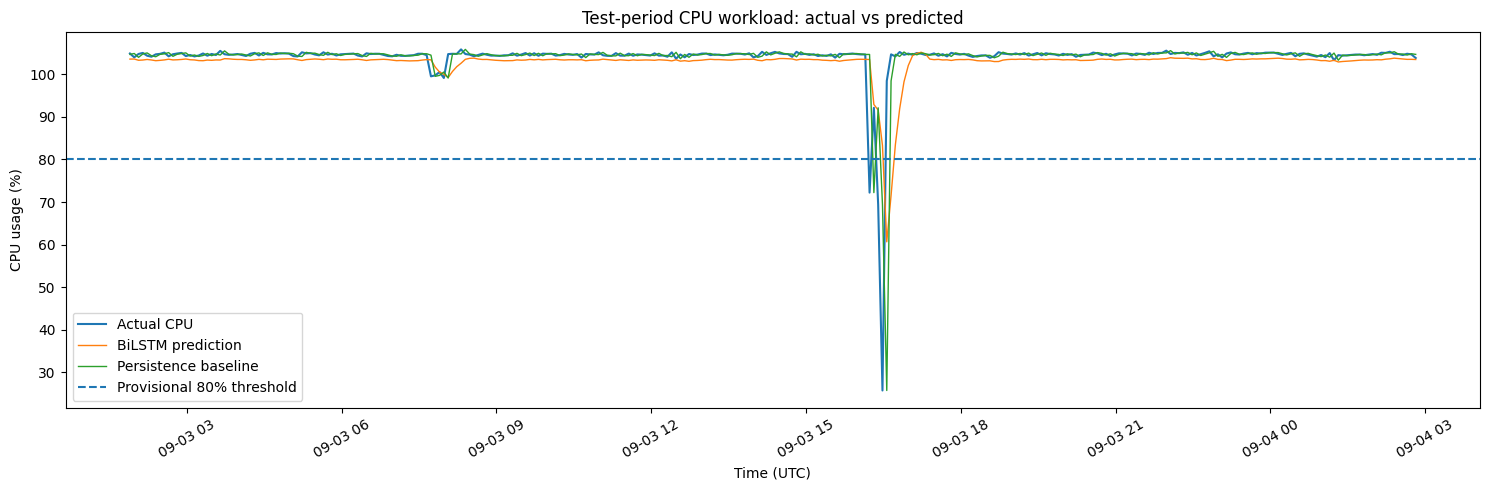

Mean absolute error by actual CPU regime:
             bilstm_abs_error        persistence_abs_error       
                        count   mean                 count   mean
cpu_regime                                                       
At/above 80%              615  2.355                   615  1.073
Below 80%                 464  4.071                   464  2.757


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Compare actual values and predictions in chronological test order
comparison = pd.DataFrame({
    "timestamp": target_times["test"],
    "actual_cpu": actual,
    "bilstm_prediction": bilstm_pred,
    "persistence_prediction": persistence_pred
}).sort_values("timestamp").reset_index(drop=True)

# Plot the first 300 test observations
n_plot = min(300, len(comparison))
plot_data = comparison.iloc[:n_plot]

plt.figure(figsize=(15, 5))
plt.plot(
    plot_data["timestamp"], plot_data["actual_cpu"],
    label="Actual CPU", linewidth=1.5
)
plt.plot(
    plot_data["timestamp"], plot_data["bilstm_prediction"],
    label="BiLSTM prediction", linewidth=1
)
plt.plot(
    plot_data["timestamp"], plot_data["persistence_prediction"],
    label="Persistence baseline", linewidth=1
)
plt.axhline(80, linestyle="--", label="Provisional 80% threshold")

plt.xlabel("Time (UTC)")
plt.ylabel("CPU usage (%)")
plt.title("Test-period CPU workload: actual vs predicted")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Compare absolute errors across the complete test period
comparison["bilstm_abs_error"] = (
    comparison["actual_cpu"] - comparison["bilstm_prediction"]
).abs()
comparison["persistence_abs_error"] = (
    comparison["actual_cpu"] - comparison["persistence_prediction"]
).abs()

print("Mean absolute error by actual CPU regime:")
comparison["cpu_regime"] = np.where(
    comparison["actual_cpu"] >= 80,
    "At/above 80%",
    "Below 80%"
)

print(
    comparison.groupby("cpu_regime")[
        ["bilstm_abs_error", "persistence_abs_error"]
    ].agg(["count", "mean"]).round(3)
)

In [ ]:
# # Inspect the 15 largest BiLSTM prediction errors
# comparison["bilstm_error"] = (
#     comparison["actual_cpu"] - comparison["bilstm_prediction"]
# )
# comparison["bilstm_abs_error"] = comparison["bilstm_error"].abs()

# largest_errors = comparison.nlargest(15, "bilstm_abs_error")[
#     [
#         "timestamp",
#         "actual_cpu",
#         "bilstm_prediction",
#         "persistence_prediction",
#         "bilstm_error",
#         "bilstm_abs_error",
#         "persistence_abs_error"
#     ]
# ]

# print(largest_errors.to_string(index=False))

                timestamp  actual_cpu  bilstm_prediction  persistence_prediction  bilstm_error  bilstm_abs_error  persistence_abs_error
2013-09-04 08:58:59+00:00    0.275000          90.266434               63.941666    -89.991432         89.991432              63.666664
2013-09-04 10:09:00+00:00  104.408333          21.570063               43.891663     82.838272         82.838272              60.516670
2013-09-06 17:44:19+00:00   92.833336          23.163219               34.450001     69.670120         69.670120              58.383335
2013-09-04 15:19:01+00:00   79.250000          13.456421               19.616667     65.793579         65.793579              59.633331
2013-09-03 16:28:52+00:00   25.683332          83.291183               69.375000    -57.607849         57.607849              43.691666
2013-09-05 11:44:08+00:00   39.775002          96.139389               84.733330    -56.364388         56.364388              44.958328
2013-09-04 09:03:59+00:00    0.250000          5

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Predict validation observations
val_pred_scaled = model.predict(X["validation"], verbose=0)

val_bilstm_pred = scaler.inverse_transform(
    val_pred_scaled.reshape(-1, 1)
).ravel()

val_actual = y_actual["validation"]

# Baselines on the same validation targets
val_persistence_pred = scaler.inverse_transform(
    X["validation"][:, -1, :]
).ravel()

val_moving_avg_pred = scaler.inverse_transform(
    X["validation"].reshape(-1, LOOKBACK)
).mean(axis=1)

validation_results = []

for name, pred in {
    "BiLSTM": val_bilstm_pred,
    "Persistence": val_persistence_pred,
    "Moving Average": val_moving_avg_pred
}.items():
    validation_results.append({
        "Model": name,
        "MAE": mean_absolute_error(val_actual, pred),
        "RMSE": np.sqrt(mean_squared_error(val_actual, pred)),
        "R2": r2_score(val_actual, pred)
    })

print("VALIDATION METRICS (CPU percentage points)")
print(pd.DataFrame(validation_results).round(4).to_string(index=False))

# Inspect the validation set's abrupt CPU changes
val_last_observed = val_persistence_pred
val_change = np.abs(val_actual - val_last_observed)

print("\nValidation observations with largest one-step CPU changes:")
val_change_df = pd.DataFrame({
    "actual_cpu": val_actual,
    "previous_cpu": val_last_observed,
    "absolute_change": val_change
}).sort_values("absolute_change", ascending=False)

print(val_change_df.head(10).round(3).to_string())

VALIDATION METRICS (CPU percentage points)
         Model    MAE   RMSE     R2
        BiLSTM 1.8716 5.2340 0.9823
   Persistence 0.8008 4.2529 0.9883
Moving Average 2.4785 9.3958 0.9429

Validation observations with largest one-step CPU changes:
     actual_cpu  previous_cpu  absolute_change
141  103.241997     27.325001        75.917000
962  103.366997     35.516998        67.849998
627   54.500000    104.682999        50.182999
629  105.067001     67.125000        37.942001
961   35.516998      0.300000        35.216999
139   36.007999      6.892000        29.117001
37    58.083000     71.833000        13.750000
838   44.025002     57.700001        13.675000
853   29.783001     43.400002        13.617000
27    86.625000     99.741997        13.117000


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Validation predictions already calculated in the previous step
actual_val = y_actual["validation"]
bilstm_val = val_bilstm_pred
persistence_val = val_persistence_pred

results = []

# Evaluate fixed blend weights selected in advance
for weight in [0.0, 0.25, 0.50, 0.75, 1.0]:
    blended = weight * bilstm_val + (1 - weight) * persistence_val

    results.append({
        "BiLSTM_weight": weight,
        "Persistence_weight": 1 - weight,
        "MAE": mean_absolute_error(actual_val, blended),
        "RMSE": np.sqrt(mean_squared_error(actual_val, blended)),
        "R2": r2_score(actual_val, blended)
    })

blend_results = pd.DataFrame(results)

print("VALIDATION-ONLY BLEND COMPARISON")
print(blend_results.round(4).to_string(index=False))

VALIDATION-ONLY BLEND COMPARISON
 BiLSTM_weight  Persistence_weight    MAE   RMSE     R2
          0.00                1.00 0.8008 4.2529 0.9883
          0.25                0.75 0.9387 4.3370 0.9878
          0.50                0.50 1.2087 4.5388 0.9867
          0.75                0.25 1.5351 4.8438 0.9848
          1.00                0.00 1.8716 5.2340 0.9823


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tf.keras.utils.set_random_seed(42)

# Learn the correction relative to the latest observed CPU value
y_train_delta = y_scaled["train"] - X["train"][:, -1, 0]
y_val_delta = y_scaled["validation"] - X["validation"][:, -1, 0]

residual_model = Sequential([
    Input(shape=(LOOKBACK, 1)),
    Bidirectional(LSTM(64, return_sequences=True)),
    Dropout(0.2),
    Bidirectional(LSTM(32)),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

residual_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

residual_history = residual_model.fit(
    X["train"],
    y_train_delta,
    validation_data=(X["validation"], y_val_delta),
    epochs=30,
    batch_size=32,
    shuffle=False,
    callbacks=callbacks,
    verbose=1
)

# Forecast = latest observed scaled CPU + predicted correction
val_delta_pred = residual_model.predict(X["validation"], verbose=0).ravel()
val_residual_scaled = X["validation"][:, -1, 0] + val_delta_pred

val_residual_pred = scaler.inverse_transform(
    val_residual_scaled.reshape(-1, 1)
).ravel()

# Compare on validation data only
val_actual = y_actual["validation"]
val_persistence = scaler.inverse_transform(
    X["validation"][:, -1, :]
).ravel()

print("\nVALIDATION RESULTS — CPU percentage points")
for name, pred in [
    ("Persistence", val_persistence),
    ("Original BiLSTM", val_bilstm_pred),
    ("Residual BiLSTM", val_residual_pred)
]:
    print(
        f"{name:20s} "
        f"MAE={mean_absolute_error(val_actual, pred):.4f} | "
        f"RMSE={np.sqrt(mean_squared_error(val_actual, pred)):.4f} | "
        f"R2={r2_score(val_actual, pred):.4f}"
    )

Epoch 1/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - loss: 0.0098 - mae: 0.0313 - val_loss: 0.0016 - val_mae: 0.0095 - learning_rate: 0.0010
Epoch 2/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.0094 - mae: 0.0264 - val_loss: 0.0016 - val_mae: 0.0106 - learning_rate: 0.0010
Epoch 3/30
155/158 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0132 - mae: 0.0349
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
158/158 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0094 - mae: 0.0268 - val_loss: 0.0016 - val_mae: 0.0101 - learning_rate: 0.0010
Epoch 4/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - loss: 0.0094 - mae: 0.0269 - val_loss: 0.0016 - val_mae: 0.0094 - learning_rate: 5.0000e-04
Epoch 5/30
156/158 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0132 - mae: 0.0337
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
158/158 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.0094 - mae: 0.0265 - val_loss: 0.0016 - val_mae: 0.0094 - learning

In [ ]:
import numpy as np

# Convert the latest input in each window back to CPU percentage points.
train_last_cpu = scaler.inverse_transform(
    X["train"][:, -1, :].reshape(-1, 1)
).ravel()

val_last_cpu = scaler.inverse_transform(
    X["validation"][:, -1, :].reshape(-1, 1)
).ravel()

# Actual changes in original CPU percentage points.
train_delta_cpu = (
    np.asarray(y_actual["train"]).ravel() - train_last_cpu
)

val_delta_cpu = (
    np.asarray(y_actual["validation"]).ravel() - val_last_cpu
)

print("Training CPU-change targets:")
print("Shape:", train_delta_cpu.shape)
print("Mean:", train_delta_cpu.mean())
print("Standard deviation:", train_delta_cpu.std())

print("\nValidation CPU-change targets:")
print("Shape:", val_delta_cpu.shape)
print("Mean:", val_delta_cpu.mean())
print("Standard deviation:", val_delta_cpu.std())

print("\nCheck for invalid values:")
print("Training NaNs:", np.isnan(train_delta_cpu).sum())
print("Validation NaNs:", np.isnan(val_delta_cpu).sum())

Training CPU-change targets:
Shape: (5035,)
Mean: 0.0003790756
Standard deviation: 10.19458

Validation CPU-change targets:
Shape: (1079,)
Mean: -0.00033207666
Standard deviation: 4.252899

Check for invalid values:
Training NaNs: 0
Validation NaNs: 0


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict the held-out test period with the residual model
test_delta_pred = residual_model.predict(X["test"], verbose=0).ravel()

test_residual_scaled = X["test"][:, -1, 0] + test_delta_pred

test_residual_pred = scaler.inverse_transform(
    test_residual_scaled.reshape(-1, 1)
).ravel()

test_actual = y_actual["test"]

# Persistence baseline on the same test targets
test_persistence = scaler.inverse_transform(
    X["test"][:, -1, :]
).ravel()

# Compare with the original BiLSTM too
test_results = []

for name, pred in [
    ("Original BiLSTM", bilstm_pred),
    ("Persistence", test_persistence),
    ("Residual BiLSTM", test_residual_pred)
]:
    test_results.append({
        "Model": name,
        "MAE": mean_absolute_error(test_actual, pred),
        "RMSE": np.sqrt(mean_squared_error(test_actual, pred)),
        "R2": r2_score(test_actual, pred)
    })

print("FINAL HELD-OUT TEST COMPARISON")
print(pd.DataFrame(test_results).round(4).to_string(index=False))

FINAL HELD-OUT TEST COMPARISON
          Model    MAE   RMSE     R2
Original BiLSTM 3.0929 9.3867 0.9633
    Persistence 1.7975 7.6497 0.9756
Residual BiLSTM 2.2424 7.6542 0.9756


In [ ]:
# STEP 1: Install and verify ARIMA

%pip install -q statsmodels

import statsmodels
from statsmodels.tsa.arima.model import ARIMA

print("ARIMA library is ready.")
print("Statsmodels version:", statsmodels.__version__)

# Verify that our existing dataset and split are available
print("\nTraining observations:", len(y_actual["train"]))
print("Validation observations:", len(y_actual["validation"]))
print("Test observations:", len(y_actual["test"]))

print("\nTraining period:")
print(target_times["train"].min(), "to", target_times["train"].max())

print("\nValidation period:")
print(target_times["validation"].min(), "to", target_times["validation"].max())

ARIMA library is ready.
Statsmodels version: 0.15.0

Training observations: 5035
Validation observations: 1079
Test observations: 1079

Training period:
2013-08-12 14:30:46+00:00 to 2013-08-30 07:53:17+00:00

Validation period:
2013-08-30 07:58:17+00:00 to 2013-09-03 01:48:47+00:00


In [ ]:
# STEP 2: Preliminary ARIMA rolling forecast

import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Original CPU values in chronological order
train_cpu = np.asarray(y_actual["train"], dtype=float)
val_cpu = np.asarray(y_actual["validation"], dtype=float)

# Fit ARIMA using training data only
arima_model = ARIMA(
    train_cpu,
    order=(2, 0, 2),
    enforce_stationarity=False,
    enforce_invertibility=False
)

arima_fit = arima_model.fit()

print("ARIMA model fitted.")
print("Model order: (2, 0, 2)")
print("Training observations:", len(train_cpu))

# Rolling one-step-ahead forecasts:
# forecast the next observation, then update with its actual value
# before forecasting the following observation.
arima_predictions = []

history = list(train_cpu)

for actual_value in val_cpu:
    fitted = ARIMA(
        history,
        order=(2, 0, 2),
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit()

    forecast_value = float(fitted.forecast(steps=1)[0])
    arima_predictions.append(forecast_value)

    history.append(float(actual_value))

arima_predictions = np.asarray(arima_predictions)

print("\nARIMA validation forecast completed.")
print("Predictions:", len(arima_predictions))
print("First 10 predictions:", np.round(arima_predictions[:10], 3))

print("\nValidation metrics:")
print("MAE:", round(mean_absolute_error(val_cpu, arima_predictions), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(val_cpu, arima_predictions)), 4))
print("R²:", round(r2_score(val_cpu, arima_predictions), 4))

ARIMA model fitted.
Model order: (2, 0, 2)
Training observations: 5035


KeyboardInterrupt: 

In [ ]:

import numpy as np
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the existing chronological training and validation data
train_cpu = np.asarray(y_actual["train"], dtype=float)
val_cpu = np.asarray(y_actual["validation"], dtype=float)

# Fit ARIMA only once
arima_fit = ARIMA(
    train_cpu,
    order=(2, 0, 2),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit()

print("Initial ARIMA model fitted.")

# Rolling one-step-ahead predictions
arima_predictions = []
current_fit = arima_fit

for i, actual_value in enumerate(val_cpu):
    # Predict the next observation BEFORE observing its actual value
    prediction = float(current_fit.forecast(steps=1)[0])
    arima_predictions.append(prediction)

    # Incorporate the actual observation without refitting parameters
    current_fit = current_fit.append(
        [actual_value],
        refit=False
    )

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(val_cpu)} observations")

arima_predictions = np.asarray(arima_predictions)

print("\nARIMA validation forecasting completed.")
print("Predictions:", len(arima_predictions))
print("MAE:", round(mean_absolute_error(val_cpu, arima_predictions), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(val_cpu, arima_predictions)), 4))
print("R²:", round(r2_score(val_cpu, arima_predictions), 4))


Initial ARIMA model fitted.
Processed 100/1079 observations
Processed 200/1079 observations
Processed 300/1079 observations
Processed 400/1079 observations
Processed 500/1079 observations
Processed 600/1079 observations
Processed 700/1079 observations
Processed 800/1079 observations
Processed 900/1079 observations
Processed 1000/1079 observations

ARIMA validation forecasting completed.
Predictions: 1079
MAE: 1.3294
RMSE: 4.6902
R²: 0.9858


In [ ]:
# Save the ARIMA validation predictions and metrics
arima_val_predictions = arima_predictions.copy()

arima_val_metrics = {
    "Model": "ARIMA(2,0,2)",
    "MAE": mean_absolute_error(val_cpu, arima_val_predictions),
    "RMSE": np.sqrt(mean_squared_error(val_cpu, arima_val_predictions)),
    "R2": r2_score(val_cpu, arima_val_predictions)
}

print(pd.DataFrame([arima_val_metrics]).round(4))

          Model     MAE    RMSE      R2
0  ARIMA(2,0,2)  1.3294  4.6902  0.9858


In [ ]:
import numpy as np
import pandas as pd

# Compare actual CPU usage with existing validation predictions
actual = np.asarray(y_actual["validation"]).flatten()
bilstm = np.asarray(val_bilstm_pred).flatten()
persistence = np.asarray(val_persistence_pred).flatten()

errors = pd.DataFrame({
    "Actual_CPU": actual,
    "BiLSTM_Predicted": bilstm,
    "Persistence_Predicted": persistence
})

errors["BiLSTM_Absolute_Error"] = np.abs(
    errors["Actual_CPU"] - errors["BiLSTM_Predicted"]
)

errors["Persistence_Absolute_Error"] = np.abs(
    errors["Actual_CPU"] - errors["Persistence_Predicted"]
)

print("Validation observations:", len(errors))
print("\nLargest 10 BiLSTM prediction errors:")
print(
    errors.nlargest(10, "BiLSTM_Absolute_Error")
    .round(3)
    .to_string(index=False)
)

Validation observations: 1079

Largest 10 BiLSTM prediction errors:
 Actual_CPU  BiLSTM_Predicted  Persistence_Predicted  BiLSTM_Absolute_Error  Persistence_Absolute_Error
 103.366997         17.319000              35.516998              86.047997                   67.849998
 103.241997         27.167000              27.325001              76.074997                   75.917000
  54.500000        103.397003             104.682999              48.896999                   50.182999
 105.050003         59.985001             103.366997              45.064999                    1.683000
 102.417000         63.734001             103.241997              38.682999                    0.825000
  35.516998          0.465000               0.300000              35.050999                   35.216999
  36.007999          4.894000               6.892000              31.114000                   29.117001
 105.067001         78.339996              67.125000              26.726999                   37.942

In [ ]:
import numpy as np

# Get validation sequences from the existing dataset dictionary
X_val_original = scaler.inverse_transform(
    X["validation"].reshape(-1, 1)
).reshape(X["validation"].shape)

actual = np.asarray(y_actual["validation"]).flatten()
predicted = np.asarray(val_bilstm_pred).flatten()

# Check that all arrays align
print("Validation input shape:", X_val_original.shape)
print("Actual values:", len(actual))
print("Predictions:", len(predicted))

# Inspect the five largest BiLSTM errors
largest_indices = np.argsort(
    np.abs(actual - predicted)
)[-5:][::-1]

for idx in largest_indices:
    previous_values = X_val_original[idx, :, 0]

    print(f"\nValidation index: {idx}")
    print("Previous 10 CPU measurements:",
          np.round(previous_values, 2))
    print("Last observed CPU:",
          round(float(previous_values[-1]), 2), "%")
    print("Actual next CPU:",
          round(float(actual[idx]), 2), "%")
    print("BiLSTM prediction:",
          round(float(predicted[idx]), 2), "%")
    print("Absolute error:",
          round(float(abs(actual[idx] - predicted[idx])), 2),
          "percentage points")

Validation input shape: (1079, 10, 1)
Actual values: 1079
Predictions: 1079

Validation index: 962
Previous 10 CPU measurements: [ 0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.3  35.52]
Last observed CPU: 35.52 %
Actual next CPU: 103.37 %
BiLSTM prediction: 17.32 %
Absolute error: 86.05 percentage points

Validation index: 141
Previous 10 CPU measurements: [ 0.35  0.37  0.34  0.34  0.34  9.34  0.34  6.89 36.01 27.32]
Last observed CPU: 27.33 %
Actual next CPU: 103.24 %
BiLSTM prediction: 27.17 %
Absolute error: 76.07 percentage points

Validation index: 627
Previous 10 CPU measurements: [104.6  104.26 104.08 104.66 104.66 104.3  104.88 104.6  104.5  104.68]
Last observed CPU: 104.68 %
Actual next CPU: 54.5 %
BiLSTM prediction: 103.4 %
Absolute error: 48.9 percentage points

Validation index: 963
Previous 10 CPU measurements: [  0.25   0.25   0.25   0.25   0.25   0.25   0.25   0.3   35.52 103.37]
Last observed CPU: 103.37 %
Actual next CPU: 105.05 %
BiLSTM prediction: 59.99 %
Absol

In [ ]:
import numpy as np
import pandas as pd

train_cpu = np.asarray(y_actual["train"]).flatten()
val_cpu = np.asarray(y_actual["validation"]).flatten()

def inspect_cpu_changes(values, name):
    changes = np.abs(np.diff(values))

    print(f"\n{name}")
    print("-" * 35)
    print("Observations:", len(values))
    print("Changes >= 10 percentage points:",
          int(np.sum(changes >= 10)))
    print("Changes >= 30 percentage points:",
          int(np.sum(changes >= 30)))
    print("Changes >= 50 percentage points:",
          int(np.sum(changes >= 50)))
    print("Largest absolute change:",
          round(float(np.max(changes)), 2),
          "percentage points")

inspect_cpu_changes(train_cpu, "TRAINING DATA")
inspect_cpu_changes(val_cpu, "VALIDATION DATA")


TRAINING DATA
-----------------------------------
Observations: 5035
Changes >= 10 percentage points: 279
Changes >= 30 percentage points: 138
Changes >= 50 percentage points: 79
Largest absolute change: 102.5 percentage points

VALIDATION DATA
-----------------------------------
Observations: 1079
Changes >= 10 percentage points: 20
Changes >= 30 percentage points: 5
Changes >= 50 percentage points: 3
Largest absolute change: 75.92 percentage points


In [ ]:
print("Type of sequence_meta:", type(sequence_meta))

if isinstance(sequence_meta, dict):
    print("Available keys:", list(sequence_meta.keys()))

elif hasattr(sequence_meta, "columns"):
    print("Available columns:", list(sequence_meta.columns))
    print("\nFirst 5 rows:")
    display(sequence_meta.head())

else:
    print("Shape:", getattr(sequence_meta, "shape", "Not available"))
    print("First 5 entries:", sequence_meta[:5])

Type of sequence_meta: <class 'pandas.core.frame.DataFrame'>
Available columns: ['segment_id', 'target_idx', 'target_time', 'actual_cpu', 'split']

First 5 rows:


,segment_id,target_idx,target_time,actual_cpu,split
0,0,10,2013-08-12 14:30:46+00:00,0.341667,train
1,0,11,2013-08-12 14:35:46+00:00,0.341667,train
2,0,12,2013-08-12 14:40:46+00:00,0.341667,train
3,0,13,2013-08-12 14:45:46+00:00,0.341667,train
4,0,14,2013-08-12 14:50:46+00:00,0.341667,train


In [ ]:
import pandas as pd

# 1. Check how many sequences belong to each split
print("Sequences in each split:")
print(sequence_meta["split"].value_counts())

# 2. Check segment distribution across splits
print("\nSegments represented in each split:")
print(
    sequence_meta.groupby("split")["segment_id"]
    .nunique()
)

# 3. Check whether segments are shared across splits
print("\nSegment distribution by split:")
display(
    pd.crosstab(
        sequence_meta["segment_id"],
        sequence_meta["split"]
    )
)

# 4. Check chronological split boundaries
print("\nTime boundaries:")
for split_name in ["train", "validation", "test"]:
    subset = sequence_meta[
        sequence_meta["split"] == split_name
    ]

    print(
        split_name,
        "| rows:", len(subset),
        "| start:", subset["target_time"].min(),
        "| end:", subset["target_time"].max()
    )

Sequences in each split:
split
train         5035
validation    1079
test          1079
Name: count, dtype: int64

Segments represented in each split:
split
test          3
train         6
validation    1
Name: segment_id, dtype: int64

Segment distribution by split:


split,test,train,validation
segment_id,,,
0,0,2961,0
3,0,703,0
4,0,290,0
6,0,329,0
7,0,391,0
8,727,361,1079
9,248,0,0
13,104,0,0



Time boundaries:
train | rows: 5035 | start: 2013-08-12 14:30:46+00:00 | end: 2013-08-30 07:53:17+00:00
validation | rows: 1079 | start: 2013-08-30 07:58:17+00:00 | end: 2013-09-03 01:48:47+00:00
test | rows: 1079 | start: 2013-09-03 01:53:47+00:00 | end: 2013-09-06 22:29:20+00:00


In [ ]:
# Inspect the available columns before checking sequence boundaries
print("working_df columns:")
print(working_df.columns.tolist())

print("\nsequence_meta columns:")
print(sequence_meta.columns.tolist())

print("\nFirst and last target indices:")
print("Minimum:", sequence_meta["target_idx"].min())
print("Maximum:", sequence_meta["target_idx"].max())

print("\nSegment counts in working_df:")
print(working_df["segment_id"].value_counts().sort_index())

working_df columns:
['Timestamp [ms]', 'CPU cores', 'CPU capacity provisioned [MHZ]', 'CPU usage [MHZ]', 'CPU usage [%]', 'Memory capacity provisioned [KB]', 'Memory usage [KB]', 'Disk read throughput [KB/s]', 'Disk write throughput [KB/s]', 'Network received throughput [KB/s]', 'Network transmitted throughput [KB/s]', 'timestamp_utc', 'gap_seconds', 'new_segment', 'segment_id']

sequence_meta columns:
['segment_id', 'target_idx', 'target_time', 'actual_cpu', 'split']

First and last target indices:
Minimum: 10
Maximum: 2970

Segment counts in working_df:
segment_id
0     2971
1        3
2        4
3      713
4      300
5        1
6      339
7      401
8     2177
9      258
10       1
11       4
12       1
13     114
Name: count, dtype: int64


In [ ]:
import numpy as np
import pandas as pd

# Verify sequence boundaries against the original dataframe
boundary_errors = []

for row in sequence_meta.itertuples(index=False):
    target_idx = int(row.target_idx)
    expected_segment = int(row.segment_id)

    # The input uses the 10 observations immediately before the target
    input_start = target_idx - 10
    input_end = target_idx  # exclusive

    if input_start < 0 or target_idx >= len(working_df):
        boundary_errors.append({
            "target_idx": target_idx,
            "reason": "Index outside dataframe"
        })
        continue

    input_segments = working_df.iloc[
        input_start:input_end
    ]["segment_id"].to_numpy()

    target_segment = working_df.iloc[target_idx]["segment_id"]

    if (
        len(input_segments) != 10
        or not np.all(input_segments == expected_segment)
        or target_segment != expected_segment
    ):
        boundary_errors.append({
            "target_idx": target_idx,
            "expected_segment": expected_segment,
            "input_segments": np.unique(input_segments).tolist(),
            "target_segment": int(target_segment)
        })

print("Total sequences checked:", len(sequence_meta))
print("Boundary errors found:", len(boundary_errors))

if boundary_errors:
    print("\nFirst 10 boundary errors:")
    print(pd.DataFrame(boundary_errors).head(10).to_string(index=False))
else:
    print("All input sequences and targets remain within their segments.")

Total sequences checked: 7193
Boundary errors found: 4232

First 10 boundary errors:
 target_idx  expected_segment input_segments  target_segment
         10                 3            [0]               0
         11                 3            [0]               0
         12                 3            [0]               0
         13                 3            [0]               0
         14                 3            [0]               0
         15                 3            [0]               0
         16                 3            [0]               0
         17                 3            [0]               0
         18                 3            [0]               0
         19                 3            [0]               0


In [ ]:
print("working_df index:")
print(working_df.index[:15].tolist())

print("\nFirst 15 metadata rows:")
display(sequence_meta.head(15))

print("\nMetadata around the first segment transition:")
display(
    sequence_meta[
        sequence_meta["segment_id"].isin([0, 3])
    ].head(15)
)

print("\nAvailable sequence variables:")
for name in ["X", "y_scaled", "y_actual", "target_times"]:
    if name in globals():
        obj = globals()[name]
        print(name, "| type:", type(obj))
        if isinstance(obj, dict):
            print("  keys:", list(obj.keys()))

working_df index:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]

First 15 metadata rows:


,segment_id,target_idx,target_time,actual_cpu,split
0,0,10,2013-08-12 14:30:46+00:00,0.341667,train
1,0,11,2013-08-12 14:35:46+00:00,0.341667,train
2,0,12,2013-08-12 14:40:46+00:00,0.341667,train
3,0,13,2013-08-12 14:45:46+00:00,0.341667,train
4,0,14,2013-08-12 14:50:46+00:00,0.341667,train
5,0,15,2013-08-12 14:55:46+00:00,0.341667,train
6,0,16,2013-08-12 15:00:46+00:00,0.366667,train
7,0,17,2013-08-12 15:05:46+00:00,0.341667,train
8,0,18,2013-08-12 15:10:46+00:00,0.575000,train
9,0,19,2013-08-12 15:15:46+00:00,0.350000,train



Metadata around the first segment transition:


,segment_id,target_idx,target_time,actual_cpu,split
0,0,10,2013-08-12 14:30:46+00:00,0.341667,train
1,0,11,2013-08-12 14:35:46+00:00,0.341667,train
2,0,12,2013-08-12 14:40:46+00:00,0.341667,train
3,0,13,2013-08-12 14:45:46+00:00,0.341667,train
4,0,14,2013-08-12 14:50:46+00:00,0.341667,train
5,0,15,2013-08-12 14:55:46+00:00,0.341667,train
6,0,16,2013-08-12 15:00:46+00:00,0.366667,train
7,0,17,2013-08-12 15:05:46+00:00,0.341667,train
8,0,18,2013-08-12 15:10:46+00:00,0.575000,train
9,0,19,2013-08-12 15:15:46+00:00,0.350000,train



Available sequence variables:
X | type: <class 'dict'>
  keys: ['train', 'validation', 'test']
y_scaled | type: <class 'dict'>
  keys: ['train', 'validation', 'test']
y_actual | type: <class 'dict'>
  keys: ['train', 'validation', 'test']
target_times | type: <class 'dict'>
  keys: ['train', 'validation', 'test']


In [ ]:
import numpy as np
import pandas as pd

# Compare the first and last metadata entries in each split
for split_name in ["train", "validation", "test"]:
    meta = sequence_meta[
        sequence_meta["split"] == split_name
    ]

    print(f"\n--- {split_name.upper()} ---")
    print("Metadata rows:", len(meta))
    print("First metadata row:")
    print(meta.head(1).to_string(index=False))
    print("Last metadata row:")
    print(meta.tail(1).to_string(index=False))

    print("Input sequence shape:", X[split_name].shape)
    print("Target array shape:", y_actual[split_name].shape)
    print("Target time count:", len(target_times[split_name]))


--- TRAIN ---
Metadata rows: 5035
First metadata row:
 segment_id  target_idx               target_time  actual_cpu split
          0          10 2013-08-12 14:30:46+00:00    0.341667 train
Last metadata row:
 segment_id  target_idx               target_time  actual_cpu split
          8         370 2013-08-30 07:53:17+00:00  105.066667 train
Input sequence shape: (5035, 10, 1)
Target array shape: (5035,)
Target time count: 5035

--- VALIDATION ---
Metadata rows: 1079
First metadata row:
 segment_id  target_idx               target_time  actual_cpu      split
          8         371 2013-08-30 07:58:17+00:00  105.016667 validation
Last metadata row:
 segment_id  target_idx               target_time  actual_cpu      split
          8        1449 2013-09-03 01:48:47+00:00  104.708333 validation
Input sequence shape: (1079, 10, 1)
Target array shape: (1079,)
Target time count: 1079

--- TEST ---
Metadata rows: 1079
First metadata row:
 segment_id  target_idx               target_time  ac

In [ ]:
import numpy as np

for split_name in ["train", "validation", "test"]:
    meta = sequence_meta[
        sequence_meta["split"] == split_name
    ].reset_index(drop=True)

    # Check target values against metadata
    target_values = np.asarray(
        y_actual[split_name]
    ).flatten()

    metadata_targets = meta["actual_cpu"].to_numpy()

    print(f"\n--- {split_name.upper()} ---")
    print(
        "Maximum target mismatch:",
        np.max(np.abs(target_values - metadata_targets))
    )

    # Check timestamps against metadata
    metadata_times = pd.to_datetime(meta["target_time"], utc=True)
    sequence_target_times = pd.to_datetime(
        target_times[split_name], utc=True
    )

    print(
        "Timestamps match:",
        np.array_equal(
            metadata_times.to_numpy(),
            sequence_target_times.to_numpy()
        )
    )


--- TRAIN ---
Maximum target mismatch: 3.5603841155307236e-06
Timestamps match: True

--- VALIDATION ---
Maximum target mismatch: 3.5603841155307236e-06
Timestamps match: True

--- TEST ---
Maximum target mismatch: 3.5603841155307236e-06
Timestamps match: True


In [ ]:
import numpy as np

for split_name in ["train", "validation", "test"]:
    meta = sequence_meta[
        sequence_meta["split"] == split_name
    ].reset_index(drop=True)

    print(f"\n--- {split_name.upper()} ---")

    for i in sorted(set([0, len(meta) - 1])):
        row = meta.iloc[i]
        segment_id = int(row["segment_id"])
        target_idx = int(row["target_idx"])

        segment_df = (
            working_df[working_df["segment_id"] == segment_id]
            .reset_index(drop=True)
        )

        expected_input = segment_df[
            "CPU usage [%]"
        ].iloc[target_idx - 10:target_idx].to_numpy()

        actual_input = scaler.inverse_transform(
            X[split_name][i].reshape(-1, 1)
        ).flatten()

        print(
            f"Sequence {i}: segment={segment_id}, "
            f"target_idx={target_idx}"
        )
        print(
            "Input matches expected history:",
            np.allclose(
                actual_input,
                expected_input,
                rtol=1e-5,
                atol=1e-4
            )
        )
        print(
            "Input segment:", segment_id,
            "| Number of historical values:", len(expected_input)
        )


--- TRAIN ---
Sequence 0: segment=0, target_idx=10
Input matches expected history: True
Input segment: 0 | Number of historical values: 10
Sequence 5034: segment=8, target_idx=370
Input matches expected history: True
Input segment: 8 | Number of historical values: 10

--- VALIDATION ---
Sequence 0: segment=8, target_idx=371
Input matches expected history: True
Input segment: 8 | Number of historical values: 10
Sequence 1078: segment=8, target_idx=1449
Input matches expected history: True
Input segment: 8 | Number of historical values: 10

--- TEST ---
Sequence 0: segment=8, target_idx=1450
Input matches expected history: True
Input segment: 8 | Number of historical values: 10
Sequence 1078: segment=13, target_idx=113
Input matches expected history: True
Input segment: 13 | Number of historical values: 10


In [ ]:
import numpy as np

total_checked = 0
input_mismatches = []
boundary_mismatches = []

for split_name in ["train", "validation", "test"]:
    meta = sequence_meta[
        sequence_meta["split"] == split_name
    ].reset_index(drop=True)

    X_original = scaler.inverse_transform(
        X[split_name].reshape(-1, 1)
    ).reshape(X[split_name].shape)

    for i, row in meta.iterrows():
        segment_id = int(row["segment_id"])
        target_idx = int(row["target_idx"])

        segment_df = (
            working_df[working_df["segment_id"] == segment_id]
            .reset_index(drop=True)
        )

        expected = segment_df[
            "CPU usage [%]"
        ].iloc[target_idx - 10:target_idx].to_numpy()

        actual_input = X_original[i, :, 0]
        total_checked += 1

        if len(expected) != 10 or not np.allclose(
            actual_input, expected, rtol=1e-5, atol=1e-4
        ):
            input_mismatches.append((split_name, i))

        if (
            target_idx >= len(segment_df)
            or segment_df.iloc[target_idx]["segment_id"] != segment_id
        ):
            boundary_mismatches.append((split_name, i))

print("Total sequences checked:", total_checked)
print("Input mismatches:", len(input_mismatches))
print("Boundary mismatches:", len(boundary_mismatches))

Total sequences checked: 7193
Input mismatches: 0
Boundary mismatches: 0


In [ ]:
# print("Current BiLSTM architecture:\n")
# model.summary()

# print("\nTraining configuration:")
# print("Optimizer:", model.optimizer.__class__.__name__)
# print("Loss:", model.loss)

# print("\nTraining history metrics:")
# print(list(history.history.keys()))

# print("\nBest validation loss epoch:")
# best_epoch = (
#     int(np.argmin(history.history["val_loss"])) + 1
# )
# print(best_epoch)

# print("Best validation loss:")
# print(round(float(min(history.history["val_loss"])), 6))


Current BiLSTM architecture:



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 10, 128)        │        33,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 228,197 (891.40 KB)

 Trainable params: 76,065 (297.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 152,132 (594.27 KB)


Training configuration:
Optimizer: Adam
Loss: mse

Training history metrics:


AttributeError: 'list' object has no attribute 'history'

In [ ]:
print("Type of history:", type(history))

if isinstance(history, dict):
    print("Available keys:", list(history.keys()))

elif isinstance(history, list):
    print("List length:", len(history))
    print("First item type:", type(history[0]) if history else "Empty list")
    print("First few items:", history[:3])

print("\nCurrent model remains available:", model is not None)

Type of history: <class 'list'>
List length: 5101
First item type: <class 'numpy.float64'>
First few items: [np.float64(0.34166666865348816), np.float64(0.34166666865348816), np.float64(0.34166666865348816)]

Current model remains available: True


In [ ]:
# Look for existing Keras History objects in the notebook's variables
import tensorflow as tf

history_objects = []

for name, obj in list(globals().items()):
    if isinstance(obj, tf.keras.callbacks.History):
        history_objects.append(name)

print("Keras History objects found:", history_objects)

print("\nCurrent model is available:", model is not None)

print("\nModel layers:")
for layer in model.layers:
    print(layer.name, "|", layer.__class__.__name__)

Keras History objects found: ['residual_history']

Current model is available: True

Model layers:
bidirectional | Bidirectional
dropout | Dropout
bidirectional_1 | Bidirectional
dropout_1 | Dropout
dense | Dense
dense_1 | Dense


In [ ]:
# Preserve the existing original BiLSTM model
bilstm_model_original = model

# Preserve its validation predictions and metrics inputs
bilstm_val_predictions_original = np.asarray(
    val_bilstm_pred
).copy()

bilstm_val_actual_original = np.asarray(
    y_actual["validation"]
).copy()

print("Original BiLSTM model preserved.")
print("Validation predictions:", len(bilstm_val_predictions_original))
print("Validation actual values:", len(bilstm_val_actual_original))
print("Model architecture:")
bilstm_model_original.summary()


Original BiLSTM model preserved.
Validation predictions: 1079
Validation actual values: 1079
Model architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 10, 128)        │        33,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 228,197 (891.40 KB)

 Trainable params: 76,065 (297.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 152,132 (594.27 KB)

In [ ]:
print("Residual BiLSTM training history keys:")
print(list(residual_history.history.keys()))

print("\nEpochs completed:")
print(len(residual_history.history["loss"]))

print("\nBest validation-loss epoch:")
best_epoch = (
    int(np.argmin(residual_history.history["val_loss"])) + 1
)
print(best_epoch)

print("\nBest validation loss:")
print(round(
    float(min(residual_history.history["val_loss"])), 6
))

print("\nLoss values from the first five epochs:")
for i in range(min(5, len(residual_history.history["loss"]))):
    print(
        f"Epoch {i + 1}: "
        f"train loss = {residual_history.history['loss'][i]:.6f}, "
        f"validation loss = {residual_history.history['val_loss'][i]:.6f}"
    )

Residual BiLSTM training history keys:
['loss', 'mae', 'val_loss', 'val_mae', 'learning_rate']

Epochs completed:
6

Best validation-loss epoch:
1

Best validation loss:
0.001615

Loss values from the first five epochs:
Epoch 1: train loss = 0.009810, validation loss = 0.001615
Epoch 2: train loss = 0.009367, validation loss = 0.001631
Epoch 3: train loss = 0.009358, validation loss = 0.001625
Epoch 4: train loss = 0.009361, validation loss = 0.001620
Epoch 5: train loss = 0.009351, validation loss = 0.001617


In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Bidirectional, LSTM, Dropout, Dense
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.utils.set_random_seed(42)

# Smaller BiLSTM architecture
bilstm_small = Sequential([
    Input(shape=(10, 1)),
    Bidirectional(LSTM(32, return_sequences=True)),
    Dropout(0.2),
    Bidirectional(LSTM(16)),
    Dropout(0.2),
    Dense(8, activation="relu"),
    Dense(1)
], name="bilstm_small")

bilstm_small.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

early_stop_small = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr_small = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

bilstm_history = bilstm_small.fit(
    X["train"],
    y_scaled["train"],
    validation_data=(X["validation"], y_scaled["validation"]),
    epochs=30,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stop_small, reduce_lr_small],
    verbose=1
)

print("\nSmall BiLSTM training completed.")
print("Trainable parameters:", bilstm_small.count_params())
print(
    "Best validation loss:",
    round(float(min(bilstm_history.history["val_loss"])), 6)
)
print(
    "Best epoch:",
    int(tf.math.argmin(bilstm_history.history["val_loss"]).numpy()) + 1
)

Epoch 1/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 19s 25ms/step - loss: 0.0498 - mae: 0.1433 - val_loss: 0.0077 - val_mae: 0.0366 - learning_rate: 0.0010
Epoch 2/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.0225 - mae: 0.0966 - val_loss: 0.0065 - val_mae: 0.0241 - learning_rate: 0.0010
Epoch 3/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.0200 - mae: 0.0899 - val_loss: 0.0078 - val_mae: 0.0587 - learning_rate: 0.0010
Epoch 4/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0190 - mae: 0.0853 - val_loss: 0.0093 - val_mae: 0.0741 - learning_rate: 0.0010
Epoch 5/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 0.0177 - mae: 0.0801 - val_loss: 0.0083 - val_mae: 0.0670 - learning_rate: 5.0000e-04
Epoch 6/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.0162 - mae: 0.0759 - val_loss: 0.0055 - val_mae: 0.0450 - learning_rate: 5.0000e-04
Epoch 7/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.0167 - mae: 0.0791 - val_loss: 0.0064 - val_mae: 0.0573 - learning_rat

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict using the smaller BiLSTM
small_val_scaled = bilstm_small.predict(
    X["validation"], verbose=0
).reshape(-1)

# Convert predictions back to CPU percentage units
small_val_pred = scaler.inverse_transform(
    small_val_scaled.reshape(-1, 1)
).reshape(-1)

small_val_actual = np.asarray(
    y_actual["validation"]
).reshape(-1)

# Calculate validation metrics
small_val_mae = mean_absolute_error(
    small_val_actual, small_val_pred
)
small_val_rmse = np.sqrt(
    mean_squared_error(small_val_actual, small_val_pred)
)
small_val_r2 = r2_score(
    small_val_actual, small_val_pred
)

print("Small BiLSTM — Validation Results")
print("MAE:", round(small_val_mae, 4))
print("RMSE:", round(small_val_rmse, 4))
print("R²:", round(small_val_r2, 4))

Small BiLSTM — Validation Results
MAE: 3.459
RMSE: 6.2458
R²: 0.9748


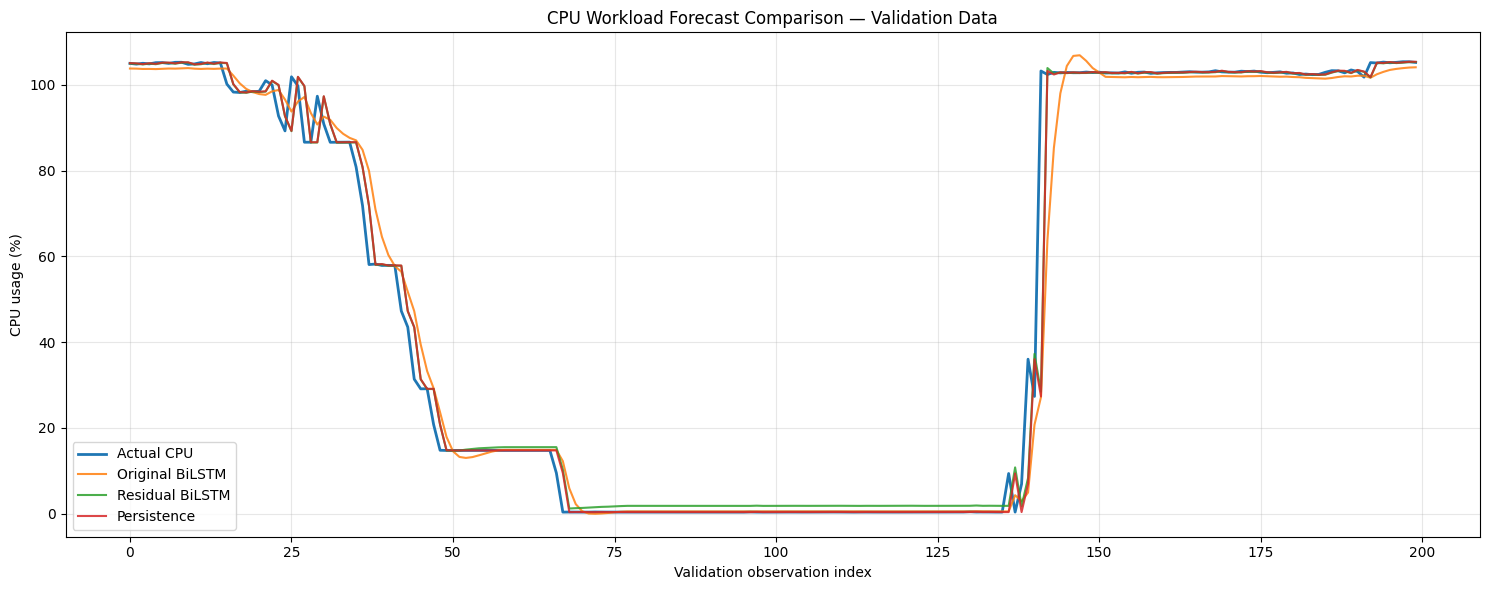

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Actual validation CPU usage
actual = np.asarray(y_actual["validation"]).flatten()

# Predictions from the existing models
original_bilstm = np.asarray(
    bilstm_val_predictions_original
).flatten()

residual_bilstm = np.asarray(
    val_residual_pred
).flatten()

persistence = np.asarray(
    val_persistence_pred
).flatten()

# Plot a 200-observation window
start = 0
end = min(start + 200, len(actual))
x = np.arange(start, end)

plt.figure(figsize=(15, 6))

plt.plot(x, actual[start:end], label="Actual CPU", linewidth=2)
plt.plot(
    x, original_bilstm[start:end],
    label="Original BiLSTM", alpha=0.85
)
plt.plot(
    x, residual_bilstm[start:end],
    label="Residual BiLSTM", alpha=0.85
)
plt.plot(
    x, persistence[start:end],
    label="Persistence", alpha=0.85
)

plt.xlabel("Validation observation index")
plt.ylabel("CPU usage (%)")
plt.title("CPU Workload Forecast Comparison — Validation Data")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = np.asarray(y_actual["validation"]).flatten()

predictions = {
    "Original BiLSTM": np.asarray(
        bilstm_val_predictions_original
    ).flatten(),
    "Residual BiLSTM": np.asarray(
        val_residual_pred
    ).flatten(),
    "Persistence": np.asarray(
        val_persistence_pred
    ).flatten()
}

# Define an abrupt change as a difference of at least
# 10 CPU percentage points between consecutive actual observations.
changes = np.abs(np.diff(actual, prepend=actual[0]))
abrupt = changes >= 10
stable = ~abrupt

rows = []

for name, pred in predictions.items():
    for group_name, mask in [
        ("Abrupt changes", abrupt),
        ("Other observations", stable)
    ]:
        if mask.sum() == 0:
            continue

        rows.append({
            "Model": name,
            "Group": group_name,
            "Count": int(mask.sum()),
            "MAE": mean_absolute_error(actual[mask], pred[mask]),
            "RMSE": np.sqrt(mean_squared_error(actual[mask], pred[mask]))
        })

results = pd.DataFrame(rows)
print(results.round(4).to_string(index=False))


          Model              Group  Count     MAE    RMSE
Original BiLSTM     Abrupt changes     20 24.4079 32.5339
Original BiLSTM Other observations   1059  1.4459  2.8146
Residual BiLSTM     Abrupt changes     20 23.0897 29.9884
Residual BiLSTM Other observations   1059  0.5878  1.1279
    Persistence     Abrupt changes     20 23.3288 30.4150
    Persistence Other observations   1059  0.3753  0.9788


In [ ]:

import numpy as np
import pandas as pd

actual = np.asarray(y_actual["validation"]).flatten()
original = np.asarray(
    bilstm_val_predictions_original
).flatten()
residual = np.asarray(val_residual_pred).flatten()
persistence = np.asarray(val_persistence_pred).flatten()

# Identify abrupt changes in actual CPU usage
changes = np.abs(np.diff(actual, prepend=actual[0]))
abrupt_indices = np.where(changes >= 10)[0]

diagnostics = pd.DataFrame({
    "Index": abrupt_indices,
    "Previous_actual_CPU": actual[np.maximum(abrupt_indices - 1, 0)],
    "Actual_CPU": actual[abrupt_indices],
    "Original_BiLSTM": original[abrupt_indices],
    "Residual_BiLSTM": residual[abrupt_indices],
    "Persistence": persistence[abrupt_indices]
})

print("Abrupt-change observations:", len(diagnostics))
print(diagnostics.round(2).to_string(index=False))


Abrupt-change observations: 20
 Index  Previous_actual_CPU  Actual_CPU  Original_BiLSTM  Residual_BiLSTM  Persistence
    25            89.269997  101.889999        93.779999        89.199997    89.269997
    27            99.739998   86.620003        97.169998        99.669998    99.739998
    29            86.620003   97.360001        90.760002        86.559998    86.620003
    37            71.830002   58.080002        79.940002        71.769997    71.830002
    42            57.860001   47.250000        56.410000        57.799999    57.860001
    44            43.490002   31.360001        47.220001        43.439999    43.490002
   139             6.890000   36.009998         4.890000         8.280000     6.890000
   141            27.320000  103.239998        27.170000        28.440001    27.320000
   627           104.680000   54.500000       103.400002       104.610001   104.680000
   628            54.500000   67.120003        87.269997        54.430000    54.500000
   629      

In [ ]:

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = np.asarray(y_actual["validation"]).flatten()
residual_pred = np.asarray(val_residual_pred).flatten()
persistence_pred = np.asarray(val_persistence_pred).flatten()

# Measure how much the residual model changes the persistence prediction
correction = residual_pred - persistence_pred

print("Residual BiLSTM correction analysis")
print("Mean correction:", round(float(np.mean(correction)), 4))
print("Mean absolute correction:", round(float(np.mean(np.abs(correction))), 4))
print("Standard deviation of correction:", round(float(np.std(correction)), 4))

# Compare forecasts on observations with the largest actual CPU changes
actual_change = np.abs(np.diff(actual, prepend=actual[0]))
abrupt_mask = actual_change >= 10

for name, pred in [
    ("Persistence", persistence_pred),
    ("Residual BiLSTM", residual_pred)
]:
    print(f"\n{name} on abrupt-change observations")
    print("Count:", int(abrupt_mask.sum()))
    print("MAE:", round(float(mean_absolute_error(
        actual[abrupt_mask], pred[abrupt_mask]
    )), 4))
    print("RMSE:", round(float(np.sqrt(mean_squared_error(
        actual[abrupt_mask], pred[abrupt_mask]
    ))), 4))


Residual BiLSTM correction analysis
Mean correction: 0.1622
Mean absolute correction: 0.2792
Standard deviation of correction: 0.523

Persistence on abrupt-change observations
Count: 20
MAE: 23.3288
RMSE: 30.415

Residual BiLSTM on abrupt-change observations
Count: 20
MAE: 23.0897
RMSE: 29.9884


In [ ]:

import numpy as np

# Compare the actual change target with the residual model's output
actual = np.asarray(y_actual["validation"]).flatten()
persistence = np.asarray(val_persistence_pred).flatten()
residual_pred = np.asarray(val_residual_pred).flatten()

actual_change = actual - persistence
predicted_change = residual_pred - persistence

print("Actual CPU change statistics:")
print("Mean:", round(float(np.mean(actual_change)), 4))
print("Std:", round(float(np.std(actual_change)), 4))
print("Minimum:", round(float(np.min(actual_change)), 4))
print("Maximum:", round(float(np.max(actual_change)), 4))

print("\nResidual model correction statistics:")
print("Mean:", round(float(np.mean(predicted_change)), 4))
print("Std:", round(float(np.std(predicted_change)), 4))
print("Minimum:", round(float(np.min(predicted_change)), 4))
print("Maximum:", round(float(np.max(predicted_change)), 4))


Actual CPU change statistics:
Mean: -0.0003
Std: 4.2529
Minimum: -50.1833
Maximum: 75.9167

Residual model correction statistics:
Mean: 0.1622
Std: 0.523
Minimum: -0.073
Maximum: 1.4583


In [ ]:

import numpy as np

print("Residual target construction check")

# Actual validation CPU values
actual = np.asarray(y_actual["validation"]).flatten()

# Last observed CPU values in the validation input sequences
last_observed_scaled = X["validation"][:, -1, 0]
last_observed = scaler.inverse_transform(
    last_observed_scaled.reshape(-1, 1)
).flatten()

# Calculate the true change in CPU percentage points
actual_residual = actual - last_observed

print("\nActual CPU values:", actual.shape)
print("Last observed CPU values:", last_observed.shape)

print("\nActual residual statistics (CPU percentage points):")
print("Mean:", round(float(np.mean(actual_residual)), 4))
print("Std:", round(float(np.std(actual_residual)), 4))
print("Minimum:", round(float(np.min(actual_residual)), 4))
print("Maximum:", round(float(np.max(actual_residual)), 4))

# Inspect the residual model's validation predictions, if available
if "residual_val_scaled" in globals():
    print("\nResidual scaled predictions found.")
    print("Shape:", np.asarray(residual_val_scaled).shape)
else:
    print("\nNo variable named residual_val_scaled found.")
    print("We will inspect the residual model's output and target scaling next.")


Residual target construction check

Actual CPU values: (1079,)
Last observed CPU values: (1079,)

Actual residual statistics (CPU percentage points):
Mean: -0.0003
Std: 4.2529
Minimum: -50.1833
Maximum: 75.9167

No variable named residual_val_scaled found.
We will inspect the residual model's output and target scaling next.


In [ ]:
import numpy as np

print("Residual model architecture:")
residual_model.summary()

print("\nAvailable residual-related variables:")
for name, obj in list(globals().items()):
    if "residual" in name.lower():
        if isinstance(obj, (np.ndarray, list)):
            try:
                arr = np.asarray(obj)
                print(f"{name}: shape={arr.shape}")
            except Exception:
                print(f"{name}: {type(obj).__name__}")
        else:
            print(f"{name}: {type(obj).__name__}")

print("\nValidation input shape:", X["validation"].shape)
print("Validation target shape:", y_scaled["validation"].shape)

Residual model architecture:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_2 (Bidirectional) │ (None, 10, 128)        │        33,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 10, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 228,197 (891.40 KB)

 Trainable params: 76,065 (297.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 152,132 (594.27 KB)


Available residual-related variables:
residual_model: Sequential
residual_history: History
val_residual_scaled: shape=(1079,)
val_residual_pred: shape=(1079,)
test_residual_scaled: shape=(1079,)
test_residual_pred: shape=(1079,)
residual_bilstm: shape=(1079,)
residual: shape=(1079,)
residual_pred: shape=(1079,)
actual_residual: shape=(1079,)

Validation input shape: (1079, 10, 1)
Validation target shape: (1079,)


In [ ]:
import numpy as np

print("1. Residual target and prediction ranges")
for name in [
    "val_residual_scaled",
    "val_residual_pred",
    "test_residual_scaled",
    "test_residual_pred",
    "actual_residual",
    "residual",
    "residual_pred"
]:
    if name in globals():
        arr = np.asarray(globals()[name]).reshape(-1)
        print(
            f"{name}: "
            f"min={arr.min():.6f}, "
            f"max={arr.max():.6f}, "
            f"mean={arr.mean():.6f}, "
            f"std={arr.std():.6f}"
        )

print("\n2. Scaler details")
print("Scaler type:", type(scaler).__name__)
print("Scaler minimum:", scaler.data_min_)
print("Scaler maximum:", scaler.data_max_)
print("Scaler scale:", scaler.scale_)

print("\n3. Residual prediction reconstruction")
print("Validation last input, scaled:",
      X["validation"][:5, -1, 0])
print("Validation actual target, scaled:",
      y_scaled["validation"][:5])
print("Validation actual target, CPU %:",
      y_actual["validation"][:5])
print("Validation residual prediction, if available:",
      np.asarray(val_residual_pred).reshape(-1)[:5])

print("\n4. Original and residual validation errors")
print("Original BiLSTM MAE:",
      np.mean(np.abs(
          np.asarray(bilstm_val_predictions_original).reshape(-1)
          - np.asarray(bilstm_val_actual_original).reshape(-1)
      )))

1. Residual target and prediction ranges
val_residual_scaled: min=0.007505, max=0.998720, mean=0.792510, std=0.368773
val_residual_pred: min=1.082093, max=105.473511, mean=83.756172, std=38.837898
test_residual_scaled: min=-0.000977, max=1.001925, mean=0.591999, std=0.459238
test_residual_pred: min=0.188770, max=105.811096, mean=62.639069, std=48.365406
actual_residual: min=-50.183334, max=75.916672, mean=-0.000332, std=4.252899
residual: min=1.082093, max=105.473511, mean=83.756172, std=38.837898
residual_pred: min=1.082093, max=105.473511, mean=83.756172, std=38.837898

2. Scaler details
Scaler type: MinMaxScaler
Scaler minimum: [0.29166666]
Scaler maximum: [105.60833]
Scaler scale: [0.00949517]

3. Residual prediction reconstruction
Validation last input, scaled: [0.99485683 0.9943821  0.9927204  0.9946194  0.99327433]
Validation actual target, scaled: [0.9943821  0.9927204  0.9946194  0.99327433 0.9959646 ]
Validation actual target, CPU %: [105.01667  104.84167  105.041664 104.9   

In [ ]:
import numpy as np

print("=== RESIDUAL TARGET CHECK ===")

# Compare the scaled target with the last observed input.
val_last_scaled = X["validation"][:, -1, 0]
val_target_scaled = y_scaled["validation"]

print("\nScaled target minus last input:")
print("Mean:", np.mean(val_target_scaled - val_last_scaled))
print("Min:", np.min(val_target_scaled - val_last_scaled))
print("Max:", np.max(val_target_scaled - val_last_scaled))

print("\nActual CPU change in percentage points:")
val_last_cpu = scaler.inverse_transform(
    val_last_scaled.reshape(-1, 1)
).ravel()

val_actual_cpu = np.asarray(y_actual["validation"]).ravel()

actual_change = val_actual_cpu - val_last_cpu

print("Mean:", np.mean(actual_change))
print("Min:", np.min(actual_change))
print("Max:", np.max(actual_change))

print("\n=== CHECK RESIDUAL MODEL OUTPUT ===")

raw_output = residual_model.predict(
    X["validation"], verbose=0
).ravel()

print("Raw model output:")
print("Min:", raw_output.min())
print("Max:", raw_output.max())
print("Mean:", raw_output.mean())

print("\nExpected scaled change, if trained on scaled differences:")
print("Mean:", np.mean(val_target_scaled - val_last_scaled))
print("Min:", np.min(val_target_scaled - val_last_scaled))
print("Max:", np.max(val_target_scaled - val_last_scaled))

=== RESIDUAL TARGET CHECK ===

Scaled target minus last input:
Mean: -3.1533564e-06
Min: -0.47649944
Max: 0.72084194

Actual CPU change in percentage points:
Mean: -0.00033207666
Min: -50.183334
Max: 75.91667

=== CHECK RESIDUAL MODEL OUTPUT ===
Raw model output:
Min: -0.000693462
Max: 0.013846745
Mean: 0.0015396903

Expected scaled change, if trained on scaled differences:
Mean: -3.1533564e-06
Min: -0.47649944
Max: 0.72084194


In [ ]:
# Inspect the variables used to train the residual model

print("Residual model input shape:", residual_model.input_shape)
print("Residual model output shape:", residual_model.output_shape)

print("\nResidual training history keys:")
print(list(residual_history.history.keys()))

print("\nTraining epochs:", len(residual_history.history["loss"]))

print("\nFirst 5 training losses:")
print(residual_history.history["loss"][:5])

print("\nFirst 5 validation losses:")
print(residual_history.history["val_loss"][:5])

Residual model input shape: (None, 10, 1)
Residual model output shape: (None, 1)

Residual training history keys:
['loss', 'mae', 'val_loss', 'val_mae', 'learning_rate']

Training epochs: 6

First 5 training losses:
[0.0098104951903224, 0.009366994723677635, 0.009358023293316364, 0.009361020289361477, 0.009351120330393314]

First 5 validation losses:
[0.0016154305776581168, 0.0016307849436998367, 0.0016249156324192882, 0.001619747024960816, 0.0016167477006092668]


In [ ]:
import numpy as np

# Compare actual scaled changes with the residual model's raw output
val_last_scaled = X["validation"][:, -1, 0]
val_target_scaled = y_scaled["validation"]

actual_scaled_change = val_target_scaled - val_last_scaled

raw_residual_output = residual_model.predict(
    X["validation"], verbose=0
).reshape(-1)

print("Actual scaled change:")
print("Mean:", actual_scaled_change.mean())
print("Standard deviation:", actual_scaled_change.std())

print("\nResidual model raw output:")
print("Mean:", raw_residual_output.mean())
print("Standard deviation:", raw_residual_output.std())

print("\nCorrelation between actual change and raw output:")
print(np.corrcoef(actual_scaled_change, raw_residual_output)[0, 1])

print("\nFirst 10 actual scaled changes:")
print(actual_scaled_change[:10])

print("\nFirst 10 raw model outputs:")
print(raw_residual_output[:10])

Actual scaled change:
Mean: -3.1533564e-06
Standard deviation: 0.040382013

Residual model raw output:
Mean: 0.0015396903
Standard deviation: 0.0049655726

Correlation between actual change and raw output:
0.10550980438578689

First 10 actual scaled changes:
[-4.7475100e-04 -1.6616583e-03  1.8990040e-03 -1.3450980e-03
  2.6902556e-03  1.5825033e-04 -1.8199086e-03  2.4529696e-03
  7.9095364e-05 -4.5893788e-03]

First 10 raw model outputs:
[-0.00069267 -0.00069266 -0.00069258 -0.0006926  -0.00069257 -0.00069259
 -0.0006927  -0.00069267 -0.00069275 -0.00069282]


In [ ]:

import numpy as np
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Predict CPU changes in ORIGINAL percentage-point units.
train_delta_cpu = np.asarray(train_delta_cpu, dtype=np.float32)
val_delta_cpu = np.asarray(val_delta_cpu, dtype=np.float32)

# New model: separate from the original BiLSTM
residual_cpu_model = Sequential([
    Input(shape=(LOOKBACK, 1)),
    Bidirectional(LSTM(64, return_sequences=True)),
    Dropout(0.2),
    Bidirectional(LSTM(32)),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
], name="residual_cpu_model")

residual_cpu_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

callbacks_cpu = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

residual_cpu_history = residual_cpu_model.fit(
    X["train"],
    train_delta_cpu,
    validation_data=(X["validation"], val_delta_cpu),
    epochs=30,
    batch_size=32,
    shuffle=False,
    callbacks=callbacks_cpu,
    verbose=1
)

print("\nTraining complete.")
print("Best validation loss:",
      min(residual_cpu_history.history["val_loss"]))
print("Best epoch:",
      np.argmin(residual_cpu_history.history["val_loss"]) + 1)


Epoch 1/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - loss: 103.8636 - mae: 2.5534 - val_loss: 17.9869 - val_mae: 0.8781 - learning_rate: 0.0010
Epoch 2/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 103.7190 - mae: 2.6521 - val_loss: 18.0083 - val_mae: 0.8893 - learning_rate: 0.0010
Epoch 3/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 103.6856 - mae: 2.6324 - val_loss: 17.9594 - val_mae: 0.8788 - learning_rate: 0.0010
Epoch 4/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 103.6000 - mae: 2.7028 - val_loss: 17.9508 - val_mae: 0.8678 - learning_rate: 0.0010
Epoch 5/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 103.4310 - mae: 2.6513 - val_loss: 17.9070 - val_mae: 0.9724 - learning_rate: 0.0010
Epoch 6/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 103.5222 - mae: 2.8283 - val_loss: 17.9485 - val_mae: 0.8850 - learning_rate: 0.0010
Epoch 7/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 145.0691 - mae: 3.5239
Epoch 7: ReduceLROnPlateau reducing lea

In [ ]:

# Reconstruct CPU forecasts from predicted CPU changes.
val_delta_cpu_pred = residual_cpu_model.predict(
    X["validation"], verbose=0
).ravel()

val_residual_cpu_forecast = val_last_cpu + val_delta_cpu_pred

val_actual_cpu = np.asarray(y_actual["validation"]).ravel()
val_persistence_cpu = val_last_cpu

print("VALIDATION RESULTS — CPU percentage points")

for name, pred in [
    ("Persistence", val_persistence_cpu),
    ("Residual CPU BiLSTM", val_residual_cpu_forecast)
]:
    print(
        f"{name:24s} "
        f"MAE={mean_absolute_error(val_actual_cpu, pred):.4f} | "
        f"RMSE={np.sqrt(mean_squared_error(val_actual_cpu, pred)):.4f} | "
        f"R2={r2_score(val_actual_cpu, pred):.4f}"
    )


VALIDATION RESULTS — CPU percentage points
Persistence              MAE=0.8008 | RMSE=4.2529 | R2=0.9883
Residual CPU BiLSTM      MAE=0.9724 | RMSE=4.2317 | R2=0.9884


In [ ]:

import numpy as np
import pandas as pd

print("=== NOTEBOOK STATE CHECK ===")

for name in [
    "working_df",
    "sequence_meta",
    "X",
    "y_actual",
    "y_scaled",
    "scaler",
    "LOOKBACK",
    "model",
    "bilstm_model_original"
]:
    if name not in globals():
        print(f"{name}: NOT FOUND")
    else:
        obj = globals()[name]
        if isinstance(obj, pd.DataFrame):
            print(f"{name}: DataFrame, shape={obj.shape}")
        elif isinstance(obj, dict):
            print(f"{name}: dict, keys={list(obj.keys())}")
        elif isinstance(obj, np.ndarray):
            print(f"{name}: array, shape={obj.shape}")
        else:
            print(f"{name}: {type(obj).__name__}")

if "sequence_meta" in globals():
    print("\nSequence split counts:")
    print(sequence_meta["split"].value_counts())

if "working_df" in globals():
    print("\nCPU column available:",
          "CPU usage [%]" in working_df.columns)
    if "timestamp_utc" in working_df.columns:
        print("Timestamp column available: True")


=== NOTEBOOK STATE CHECK ===
working_df: DataFrame, shape=(7287, 15)
sequence_meta: DataFrame, shape=(7193, 5)
X: dict, keys=['train', 'validation', 'test']
y_actual: dict, keys=['train', 'validation', 'test']
y_scaled: dict, keys=['train', 'validation', 'test']
scaler: MinMaxScaler
LOOKBACK: int
model: Sequential
bilstm_model_original: Sequential

Sequence split counts:
split
train         5035
validation    1079
test          1079
Name: count, dtype: int64

CPU column available: True
Timestamp column available: True


In [ ]:

import numpy as np
import pandas as pd

# Verify the CPU values and target timestamps for each split.
cpu_col = "CPU usage [%]"

print("=== CURRENT SCALER ===")
print("Scaler minimum:", scaler.data_min_)
print("Scaler maximum:", scaler.data_max_)

print("\n=== CHRONOLOGICAL SPLITS ===")
for split_name in ["train", "validation", "test"]:
    meta = sequence_meta[
        sequence_meta["split"] == split_name
    ]

    print(f"\n{split_name.upper()}")
    print("Sequences:", len(meta))
    print("First target:", meta["target_time"].min())
    print("Last target:", meta["target_time"].max())

# Compare the scaler range with training-period CPU observations.
train_meta = sequence_meta[
    sequence_meta["split"] == "train"
]

train_target_end = train_meta["target_idx"].max()

print("\n=== SCALER FIT CHECK ===")
print("Training target index maximum:", train_target_end)
print(
    "Current scaler data range:",
    float(scaler.data_min_[0]),
    "to",
    float(scaler.data_max_[0])
)
print(
    "\nNote: these checks do not prove which observations "
    "were used to fit the scaler."
)


=== CURRENT SCALER ===
Scaler minimum: [0.29166666]
Scaler maximum: [105.60833]

=== CHRONOLOGICAL SPLITS ===

TRAIN
Sequences: 5035
First target: 2013-08-12 14:30:46+00:00
Last target: 2013-08-30 07:53:17+00:00

VALIDATION
Sequences: 1079
First target: 2013-08-30 07:58:17+00:00
Last target: 2013-09-03 01:48:47+00:00

TEST
Sequences: 1079
First target: 2013-09-03 01:53:47+00:00
Last target: 2013-09-06 22:29:20+00:00

=== SCALER FIT CHECK ===
Training target index maximum: 2970
Current scaler data range: 0.2916666567325592 to 105.60832977294922

Note: these checks do not prove which observations were used to fit the scaler.


In [ ]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# Find the final training target timestamp.
train_meta = sequence_meta[
    sequence_meta["split"] == "train"
]
train_cutoff = train_meta["target_time"].max()

# Locate the matching timestamp in the original dataframe.
train_cutoff_rows = working_df.index[
    working_df["timestamp_utc"] == train_cutoff
]

print("Training cutoff:", train_cutoff)
print("Matching dataframe rows:", len(train_cutoff_rows))

if len(train_cutoff_rows) != 1:
    print(
        "Timestamp does not map uniquely to a dataframe row. "
        "Stop here; do not refit the scaler yet."
    )
else:
    cutoff_position = working_df.index.get_loc(
        train_cutoff_rows[0]
    )

    cpu = working_df["CPU usage [%]"].astype(float)

    train_cpu_raw = cpu.iloc[:cutoff_position + 1].to_numpy()
    all_cpu_raw = cpu.to_numpy()

    print("\nTraining-period raw CPU range:")
    print("Min:", np.nanmin(train_cpu_raw))
    print("Max:", np.nanmax(train_cpu_raw))

    print("\nFull-series raw CPU range:")
    print("Min:", np.nanmin(all_cpu_raw))
    print("Max:", np.nanmax(all_cpu_raw))

    print("\nExisting scaler range:")
    print("Min:", float(scaler.data_min_[0]))
    print("Max:", float(scaler.data_max_[0]))

    print("\nTraining observations:", len(train_cpu_raw))
    print("Cutoff dataframe position:", cutoff_position)


Training cutoff: 2013-08-30 07:53:17+00:00
Matching dataframe rows: 1

Training-period raw CPU range:
Min: 0.2916666666666667
Max: 105.60833333333332

Full-series raw CPU range:
Min: 0.25
Max: 105.88333333333334

Existing scaler range:
Min: 0.2916666567325592
Max: 105.60832977294922

Training observations: 5103
Cutoff dataframe position: 5102


In [ ]:

print("=== SEQUENCE VALIDATION ===")

print("Lookback:", LOOKBACK)
print("Train X:", X["train"].shape)
print("Validation X:", X["validation"].shape)
print("Test X:", X["test"].shape)

print("\nTarget counts:")
for split_name in ["train", "validation", "test"]:
    print(
        split_name,
        "inputs =", len(X[split_name]),
        "targets =", len(y_actual[split_name])
    )

print("\nSequence split counts:")
print(sequence_meta["split"].value_counts())

print("\nTimestamp ranges:")
for split_name in ["train", "validation", "test"]:
    meta = sequence_meta[sequence_meta["split"] == split_name]
    print(
        f"{split_name}: "
        f"{meta['target_time'].min()} -> "
        f"{meta['target_time'].max()}"
    )

print("\nScaler fitted range:")
print("Min:", float(scaler.data_min_[0]))
print("Max:", float(scaler.data_max_[0]))


=== SEQUENCE VALIDATION ===
Lookback: 10
Train X: (5035, 10, 1)
Validation X: (1079, 10, 1)
Test X: (1079, 10, 1)

Target counts:
train inputs = 5035 targets = 5035
validation inputs = 1079 targets = 1079
test inputs = 1079 targets = 1079

Sequence split counts:
split
train         5035
validation    1079
test          1079
Name: count, dtype: int64

Timestamp ranges:
train: 2013-08-12 14:30:46+00:00 -> 2013-08-30 07:53:17+00:00
validation: 2013-08-30 07:58:17+00:00 -> 2013-09-03 01:48:47+00:00
test: 2013-09-03 01:53:47+00:00 -> 2013-09-06 22:29:20+00:00

Scaler fitted range:
Min: 0.2916666567325592
Max: 105.60832977294922


In [ ]:

import numpy as np
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Preserve the previous model and create a fresh model.
bilstm_corrected = Sequential([
    Input(shape=(LOOKBACK, 1)),
    Bidirectional(LSTM(64, return_sequences=True)),
    Dropout(0.2),
    Bidirectional(LSTM(32)),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
], name="bilstm_corrected")

bilstm_corrected.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

callbacks_corrected = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history_corrected = bilstm_corrected.fit(
    X["train"],
    y_scaled["train"],
    validation_data=(
        X["validation"],
        y_scaled["validation"]
    ),
    epochs=30,
    batch_size=32,
    shuffle=False,
    callbacks=callbacks_corrected,
    verbose=1
)

print("\nCorrected BiLSTM training completed.")
print(
    "Best epoch:",
    np.argmin(history_corrected.history["val_loss"]) + 1
)
print(
    "Best validation loss:",
    min(history_corrected.history["val_loss"])
)


Epoch 1/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 14s 31ms/step - loss: 0.0478 - mae: 0.1470 - val_loss: 0.0078 - val_mae: 0.0408 - learning_rate: 0.0010
Epoch 2/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 0.0208 - mae: 0.0881 - val_loss: 0.0076 - val_mae: 0.0503 - learning_rate: 0.0010
Epoch 3/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.0195 - mae: 0.0867 - val_loss: 0.0087 - val_mae: 0.0669 - learning_rate: 0.0010
Epoch 4/30
156/158 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0218 - mae: 0.0910
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
158/158 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.0177 - mae: 0.0818 - val_loss: 0.0095 - val_mae: 0.0773 - learning_rate: 0.0010
Epoch 5/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0155 - mae: 0.0734 - val_loss: 0.0044 - val_mae: 0.0327 - learning_rate: 5.0000e-04
Epoch 6/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 0.0144 - mae: 0.0705 - val_loss: 0.0041 - val_mae: 0.0349 - learning_rat

In [ ]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Generate BiLSTM predictions in scaled units.
test_pred_scaled = bilstm_corrected.predict(
    X["test"], verbose=0
).reshape(-1, 1)

# 2. Convert predictions and actual targets to CPU percentage points.
test_pred_cpu = scaler.inverse_transform(
    test_pred_scaled
).ravel()

test_actual_cpu = np.asarray(
    y_actual["test"]
).ravel()

# 3. Persistence: predict the next CPU value using the latest input.
test_last_scaled = X["test"][:, -1, :]

test_persistence_cpu = scaler.inverse_transform(
    test_last_scaled
).ravel()

# 4. Verify that all arrays align.
assert len(test_pred_cpu) == len(test_actual_cpu)
assert len(test_persistence_cpu) == len(test_actual_cpu)

print("TEST RESULTS — CPU percentage points")
print("Same test timestamps:", len(test_actual_cpu))

test_metrics = []

for name, pred in [
    ("BiLSTM corrected", test_pred_cpu),
    ("Persistence", test_persistence_cpu)
]:
    mae = mean_absolute_error(test_actual_cpu, pred)
    rmse = np.sqrt(mean_squared_error(test_actual_cpu, pred))
    r2 = r2_score(test_actual_cpu, pred)

    test_metrics.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    print(
        f"{name:20s} "
        f"MAE={mae:.4f} | "
        f"RMSE={rmse:.4f} | "
        f"R2={r2:.4f}"
    )

test_metrics_df = pd.DataFrame(test_metrics)


TEST RESULTS — CPU percentage points
Same test timestamps: 1079
BiLSTM corrected     MAE=3.0929 | RMSE=9.3867 | R2=0.9633
Persistence          MAE=1.7975 | RMSE=7.6497 | R2=0.9756


In [ ]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

OVERLOAD_THRESHOLD = 80.0

actual_overload = (
    test_actual_cpu >= OVERLOAD_THRESHOLD
).astype(int)

overload_results = []

for name, pred in [
    ("BiLSTM corrected", test_pred_cpu),
    ("Persistence", test_persistence_cpu)
]:
    predicted_overload = (
        pred >= OVERLOAD_THRESHOLD
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        actual_overload,
        predicted_overload,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        actual_overload,
        predicted_overload,
        zero_division=0
    )
    recall = recall_score(
        actual_overload,
        predicted_overload,
        zero_division=0
    )
    f1 = f1_score(
        actual_overload,
        predicted_overload,
        zero_division=0
    )

    overload_results.append({
        "Model": name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

overload_metrics_df = pd.DataFrame(overload_results)

print("OVERLOAD DETECTION RESULTS")
print("Threshold:", OVERLOAD_THRESHOLD, "% CPU")
print("Actual overload events:", int(actual_overload.sum()))
display(overload_metrics_df.round(4))


OVERLOAD DETECTION RESULTS
Threshold: 80.0 % CPU
Actual overload events: 615


,Model,TN,FP,FN,TP,Precision,Recall,F1
0,BiLSTM corrected,454,10,11,604,0.9837,0.9821,0.9829
1,Persistence,456,8,7,608,0.9870,0.9886,0.9878


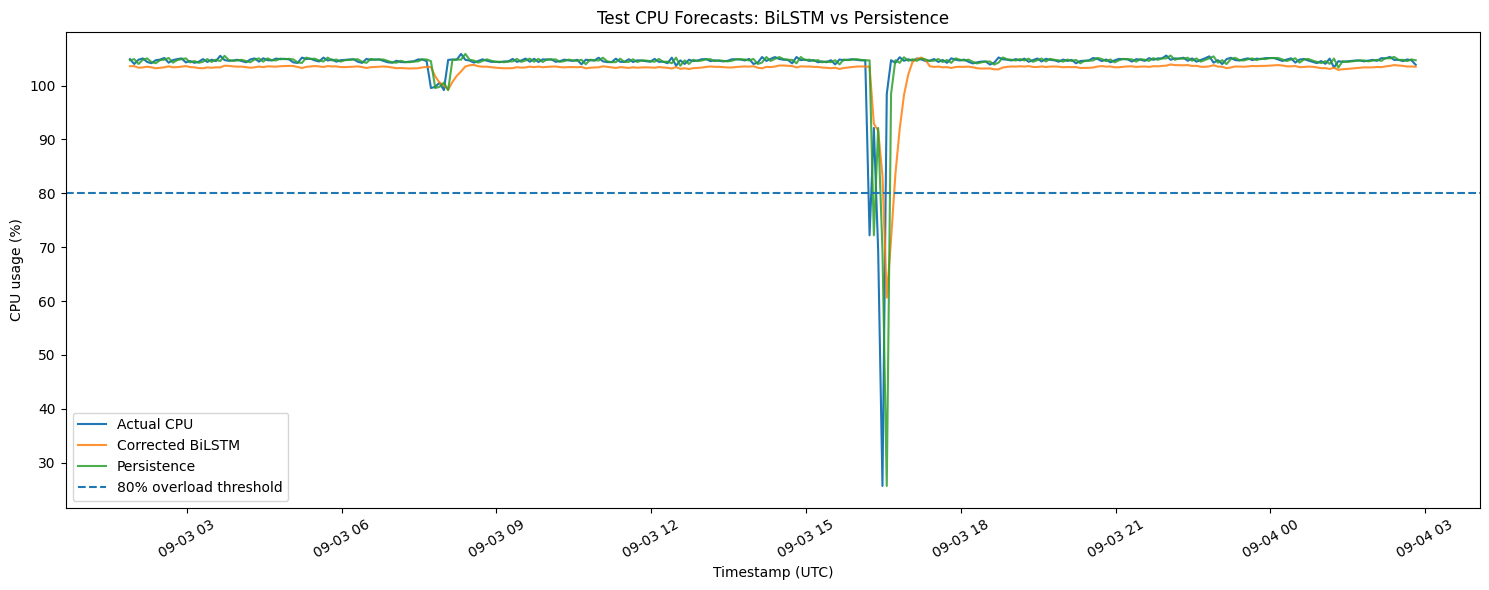

Saved:
- updated_cpu_predictions.csv
- updated_forecast_metrics.csv
- updated_overload_metrics.csv
- updated_prediction_graph.png

Prediction CSV preview:


,timestamp_utc,actual_cpu_percent,bilstm_predicted_cpu_percent,persistence_predicted_cpu_percent,actual_overload,bilstm_predicted_overload,persistence_predicted_overload
0,2013-09-03 01:53:47+00:00,104.916664,103.602013,104.708336,1,1,1
1,2013-09-03 01:58:47+00:00,104.016670,103.616966,104.916664,1,1,1
2,2013-09-03 02:03:47+00:00,104.808334,103.323296,104.016670,1,1,1
3,2013-09-03 02:08:47+00:00,105.050003,103.383865,104.808334,1,1,1
4,2013-09-03 02:13:47+00:00,104.391670,103.517883,105.050003,1,1,1


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Extract test target timestamps in their existing sequence order.
test_meta = (
    sequence_meta[sequence_meta["split"] == "test"]
    .copy()
    .reset_index(drop=True)
)

assert len(test_meta) == len(test_actual_cpu)

# Create the updated prediction file.
updated_predictions = pd.DataFrame({
    "timestamp_utc": test_meta["target_time"],
    "actual_cpu_percent": test_actual_cpu,
    "bilstm_predicted_cpu_percent": test_pred_cpu,
    "persistence_predicted_cpu_percent": test_persistence_cpu,
    "actual_overload": (
        test_actual_cpu >= OVERLOAD_THRESHOLD
    ).astype(int),
    "bilstm_predicted_overload": (
        test_pred_cpu >= OVERLOAD_THRESHOLD
    ).astype(int),
    "persistence_predicted_overload": (
        test_persistence_cpu >= OVERLOAD_THRESHOLD
    ).astype(int)
})

updated_predictions.to_csv(
    "updated_cpu_predictions.csv",
    index=False
)

test_metrics_df.to_csv(
    "updated_forecast_metrics.csv",
    index=False
)

overload_metrics_df.to_csv(
    "updated_overload_metrics.csv",
    index=False
)

# Plot a readable sample of the test period.
plot_n = min(300, len(updated_predictions))
plot_data = updated_predictions.iloc[:plot_n]

plt.figure(figsize=(15, 6))
plt.plot(
    plot_data["timestamp_utc"],
    plot_data["actual_cpu_percent"],
    label="Actual CPU",
    linewidth=1.5
)
plt.plot(
    plot_data["timestamp_utc"],
    plot_data["bilstm_predicted_cpu_percent"],
    label="Corrected BiLSTM",
    alpha=0.85
)
plt.plot(
    plot_data["timestamp_utc"],
    plot_data["persistence_predicted_cpu_percent"],
    label="Persistence",
    alpha=0.85
)
plt.axhline(
    OVERLOAD_THRESHOLD,
    linestyle="--",
    label="80% overload threshold"
)
plt.xlabel("Timestamp (UTC)")
plt.ylabel("CPU usage (%)")
plt.title("Test CPU Forecasts: BiLSTM vs Persistence")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("updated_prediction_graph.png", dpi=200)
plt.show()

print("Saved:")
print("- updated_cpu_predictions.csv")
print("- updated_forecast_metrics.csv")
print("- updated_overload_metrics.csv")
print("- updated_prediction_graph.png")

print("\nPrediction CSV preview:")
display(updated_predictions.head())


In [ ]:

import joblib
import json
import os

# Save the corrected BiLSTM.
bilstm_corrected.save("bilstm_corrected.keras")

# Save the fitted training-only scaler.
joblib.dump(scaler, "bilstm_scaler.joblib")

# Save configuration needed to interpret model inputs.
config = {
    "model_name": "Corrected BiLSTM",
    "lookback": int(LOOKBACK),
    "target": "CPU usage [%]",
    "forecast_horizon": "Next observation",
    "overload_threshold_percent": 80.0,
    "input_shape": [int(LOOKBACK), 1],
    "test_observations": int(len(test_actual_cpu)),
    "note": (
        "One-step-ahead forecasts. Test period was inspected "
        "during earlier experiments; results are not an "
        "untouched final evaluation."
    )
}

with open("bilstm_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Saved model, scaler and configuration:")
print("- bilstm_corrected.keras")
print("- bilstm_scaler.joblib")
print("- bilstm_config.json")


Saved model, scaler and configuration:
- bilstm_corrected.keras
- bilstm_scaler.joblib
- bilstm_config.json


In [ ]:

import os
import zipfile

files_to_package = [
    "updated_cpu_predictions.csv",
    "updated_forecast_metrics.csv",
    "updated_overload_metrics.csv",
    "updated_prediction_graph.png",
    "bilstm_corrected.keras",
    "bilstm_scaler.joblib",
    "bilstm_config.json",
]

# Check that every required file exists before packaging.
missing = [
    filename for filename in files_to_package
    if not os.path.exists(filename)
]

if missing:
    print("These files are missing:")
    for filename in missing:
        print("-", filename)
    print("\nCheck your Colab working directory.")
else:
    readme = """PERSON 1 - BiLSTM WORKLOAD PREDICTION

Contents:
- updated_cpu_predictions.csv: test predictions and actual values
- updated_forecast_metrics.csv: MAE, RMSE and R2
- updated_overload_metrics.csv: overload confusion matrix and metrics
- updated_prediction_graph.png: forecast comparison graph
- bilstm_corrected.keras: trained BiLSTM model
- bilstm_scaler.joblib: fitted MinMaxScaler
- bilstm_config.json: model configuration and limitations

Model:
- Input: previous 10 CPU observations
- Forecast: next CPU observation
- Overload threshold: 80 percent CPU
- Test observations: 1079

Important:
Persistence outperformed BiLSTM on the reported test MAE,
RMSE, R2, precision, recall and F1-score.

The test period was inspected during earlier experiments.
These results are not an untouched final evaluation.

The actual CPU values in the prediction CSV are for evaluation.
Do not provide future actual values to the scheduler as inputs.

Before deployment, verify model loading, preprocessing, timestamps,
and the forecast interface expected by Person 2.
"""

    with open("PERSON1_README.txt", "w", encoding="utf-8") as f:
        f.write(readme)

    package_files = files_to_package + ["PERSON1_README.txt"]
    zip_name = "Person1_BiLSTM_Handover.zip"

    with zipfile.ZipFile(
        zip_name, "w", zipfile.ZIP_DEFLATED
    ) as zf:
        for filename in package_files:
            zf.write(filename, arcname=filename)

    print("Handover package created:", zip_name)
    print("\nFiles included:")
    for filename in package_files:
        print("-", filename)

    print("\nZIP size:", round(os.path.getsize(zip_name) / 1024, 2), "KB")

    # Download the ZIP to your computer.
    from google.colab import files
    files.download(zip_name)


Handover package created: Person1_BiLSTM_Handover.zip

Files included:
- updated_cpu_predictions.csv
- updated_forecast_metrics.csv
- updated_overload_metrics.csv
- updated_prediction_graph.png
- bilstm_corrected.keras
- bilstm_scaler.joblib
- bilstm_config.json
- PERSON1_README.txt

ZIP size: 1021.68 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download("updated_cpu_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>